In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [4]:
ruta_metricas = "ca_cliente_metricas_12m.csv"
ruta_resumen = "ca_cohortes_resumen.csv"

df_clientes = pd.read_csv(ruta_metricas)
df_resumen = pd.read_csv(ruta_resumen)

In [5]:
display(df_clientes.head())

,codigo_cliente,fecha_inicio_cliente,mes_conversion,orden_cohorte,cohorte,ventana_12m_completa,venta_total_12m,venta_etica_12m,venta_otras_12m,participacion_etica_pct,descuento_total_12m,unidades_12m,facturas_12m,facturas_etica_12m,facturas_no_etica_12m,ticket_promedio_12m,ticket_maximo_12m,ticket_minimo_12m,meses_con_compra_12m,meses_con_compra_etica_12m,meses_con_compra_no_etica_12m,recurrencia_12m,venta_promedio_mes_activo,facturas_promedio_mes_activo,max_productos_distintos_mes,max_productos_etica_mes,max_productos_no_etica_mes,max_lineas_distintas_mes
0,C4507632010,2022-07-01,1.00,1,Convertido mes 1,1,"17,960.41","2,478.39","15,469.00",13.80,"3,042.79",328.00,26,10,25,690.79,"3,556.91",84.62,12,7,12,1.00,"1,496.70",2.00,10,3,9,4
1,C1765380017,2023-05-01,NaN,99,Nunca Etico,1,617.78,0.00,617.00,0.00,104.62,4.00,2,0,2,308.89,321.30,296.48,2,0,2,0.17,308.89,1.00,1,0,1,1
2,C5899292017,2022-08-01,0.00,0,Nacido Etico,1,"4,456.26",521.69,"3,932.00",11.71,"1,125.54",52.00,6,4,6,742.71,"2,001.80",292.31,6,4,6,0.50,742.71,1.00,5,2,4,3
3,C4008430016,2022-07-01,0.00,0,Nacido Etico,1,"23,176.67","6,099.51","17,072.00",26.32,"3,963.73",314.00,10,10,10,"2,317.67","3,648.83",727.64,8,8,8,0.67,"2,897.08",1.00,23,7,18,4
4,C5353259017,2025-04-01,6.00,6,Convertido mes 6,1,"5,375.10",237.03,"5,135.00",4.41,"1,591.12",74.00,7,1,6,767.87,"1,626.12",237.03,6,1,6,0.50,895.85,1.00,3,2,3,2


In [4]:
display(df_resumen.head(15))

,cohorte,orden_cohorte,clientes,venta_promedio,mediana_venta,venta_etica_promedio,venta_otras_promedio,participacion_etica_promedio,ticket_promedio,facturas_promedio,unidades_promedio,meses_activos_promedio,recurrencia_promedio,productos_promedio,lineas_promedio
0,Nacido Etico,0,3893,"25,127.24","6,206.68","5,706.94","19,413.57",28.94,"1,236.69",15.42,447.29,6.49,0.54,12.67,3.57
1,Convertido mes 1,1,410,"20,252.80","6,602.30","3,466.30","16,778.80",22.34,990.45,16.93,336.86,7.92,0.66,10.10,3.43
2,Convertido mes 2,2,274,"11,133.47","5,490.68","1,874.69","9,253.90",18.80,927.37,10.74,205.39,7.16,0.60,8.61,3.25
3,Convertido mes 3,3,188,"8,367.94","4,644.94","1,294.08","7,070.03",18.42,924.25,8.40,216.39,6.18,0.52,8.17,3.06
4,Convertido mes 4,4,122,"8,874.70","3,739.52","1,255.68","7,615.26",17.17,"1,038.75",8.25,283.75,5.75,0.48,7.29,2.82
5,Convertido mes 5,5,103,"14,119.10","3,246.35","1,512.27","12,603.37",14.24,"1,910.80",7.85,798.57,5.47,0.46,7.38,2.84
6,Convertido mes 6,6,72,"30,949.08","3,435.69","4,127.58","26,817.43",17.26,"1,841.63",9.04,669.85,5.62,0.47,7.28,2.58
7,Convertido mes 7,7,51,"9,329.14","3,002.63","2,088.79","7,237.63",14.26,"1,597.11",6.02,260.41,4.45,0.37,6.39,2.63
8,Convertido mes 8,8,48,"4,733.17","2,264.40",836.44,"3,894.00",12.49,902.92,6.56,197.71,4.94,0.41,5.73,2.52
9,Convertido mes 9,9,47,"5,779.37","2,525.76",747.50,"5,028.98",13.55,"1,082.88",6.47,202.19,4.89,0.41,5.85,2.70


In [6]:
def normalizar_columnas(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )
    return df


df_clientes = normalizar_columnas(df_clientes)
df_resumen = normalizar_columnas(df_resumen)

In [6]:
print(df_clientes.columns.tolist())

['codigo_cliente', 'fecha_inicio_cliente', 'mes_conversion', 'orden_cohorte', 'cohorte', 'ventana_12m_completa', 'venta_total_12m', 'venta_etica_12m', 'venta_otras_12m', 'participacion_etica_pct', 'descuento_total_12m', 'unidades_12m', 'facturas_12m', 'facturas_etica_12m', 'facturas_no_etica_12m', 'ticket_promedio_12m', 'ticket_maximo_12m', 'ticket_minimo_12m', 'meses_con_compra_12m', 'meses_con_compra_etica_12m', 'meses_con_compra_no_etica_12m', 'recurrencia_12m', 'venta_promedio_mes_activo', 'facturas_promedio_mes_activo', 'max_productos_distintos_mes', 'max_productos_etica_mes', 'max_productos_no_etica_mes', 'max_lineas_distintas_mes']


In [7]:
print(df_resumen.columns.tolist())

['cohorte', 'orden_cohorte', 'clientes', 'venta_promedio', 'mediana_venta', 'venta_etica_promedio', 'venta_otras_promedio', 'participacion_etica_promedio', 'ticket_promedio', 'facturas_promedio', 'unidades_promedio', 'meses_activos_promedio', 'recurrencia_promedio', 'productos_promedio', 'lineas_promedio']


In [7]:
cantidad_filas = len(df_clientes)
cantidad_clientes = df_clientes["codigo_cliente"].nunique()

print("Cantidad de filas:", cantidad_filas)
print("Clientes únicos:", cantidad_clientes)
print("Diferencia:", cantidad_filas - cantidad_clientes)

Cantidad de filas: 6881
Clientes únicos: 6881
Diferencia: 0


In [9]:
duplicados = (
    df_clientes
    .groupby("codigo_cliente")
    .size()
    .reset_index(name="cantidad")
    .query("cantidad > 1")
)

print("Clientes duplicados:", len(duplicados))

Clientes duplicados: 0


In [8]:
if "ventana_12m_completa" in df_clientes.columns:
    print(
        df_clientes["ventana_12m_completa"]
        .value_counts(dropna=False)
    )

ventana_12m_completa
1    6881
Name: count, dtype: int64


In [9]:
df_clientes = df_clientes[
    df_clientes["ventana_12m_completa"] == 1
].copy()

In [10]:
df_clientes["orden_cohorte"] = pd.to_numeric(
    df_clientes["orden_cohorte"],
    errors="coerce"
)

df_resumen["orden_cohorte"] = pd.to_numeric(
    df_resumen["orden_cohorte"],
    errors="coerce"
)

df_clientes = df_clientes.sort_values("orden_cohorte")
df_resumen = df_resumen.sort_values("orden_cohorte")

In [11]:
def etiqueta_cohorte(orden):
    if orden == 0:
        return "Nacido Ético"
    elif 1 <= orden <= 11:
        return f"Mes {int(orden)}"
    elif orden == 99:
        return "Nunca Ético"
    return str(orden)


df_resumen["etiqueta_cohorte"] = (
    df_resumen["orden_cohorte"]
    .apply(etiqueta_cohorte)
)

In [12]:
columnas_resumen = [
    "cohorte",
    "orden_cohorte",
    "clientes",
    "venta_promedio",
    "mediana_venta",
    "ticket_promedio",
    "facturas_promedio",
    "meses_activos_promedio",
    "recurrencia_promedio"
]

columnas_existentes = [
    columna
    for columna in columnas_resumen
    if columna in df_resumen.columns
]

display(
    df_resumen[columnas_existentes]
    .sort_values("orden_cohorte")
)

,cohorte,orden_cohorte,clientes,venta_promedio,mediana_venta,ticket_promedio,facturas_promedio,meses_activos_promedio,recurrencia_promedio
0,Nacido Etico,0,3893,"25,127.24","6,206.68","1,236.69",15.42,6.49,0.54
1,Convertido mes 1,1,410,"20,252.80","6,602.30",990.45,16.93,7.92,0.66
2,Convertido mes 2,2,274,"11,133.47","5,490.68",927.37,10.74,7.16,0.60
3,Convertido mes 3,3,188,"8,367.94","4,644.94",924.25,8.40,6.18,0.52
4,Convertido mes 4,4,122,"8,874.70","3,739.52","1,038.75",8.25,5.75,0.48
5,Convertido mes 5,5,103,"14,119.10","3,246.35","1,910.80",7.85,5.47,0.46
6,Convertido mes 6,6,72,"30,949.08","3,435.69","1,841.63",9.04,5.62,0.47
7,Convertido mes 7,7,51,"9,329.14","3,002.63","1,597.11",6.02,4.45,0.37
8,Convertido mes 8,8,48,"4,733.17","2,264.40",902.92,6.56,4.94,0.41
9,Convertido mes 9,9,47,"5,779.37","2,525.76","1,082.88",6.47,4.89,0.41


In [13]:
df_resumen.to_excel("resumen_conversion.xlsx", index=False)

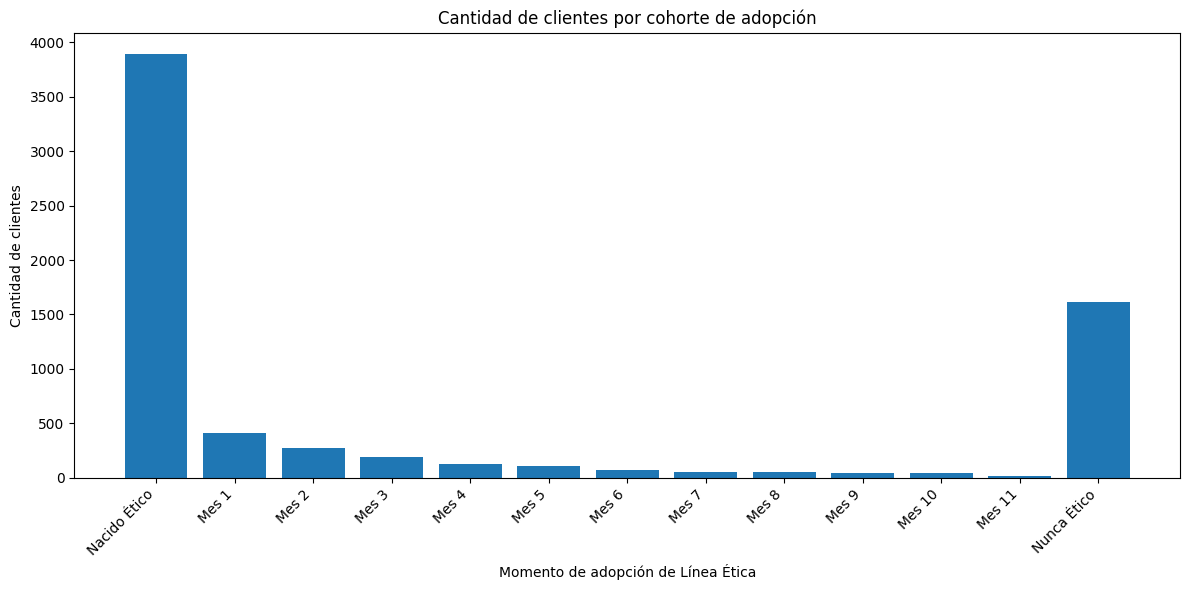

In [14]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["clientes"]
)

plt.title("Cantidad de clientes por cohorte de adopción")
plt.xlabel("Momento de adopción de Línea Ética")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
df_resumen["participacion_clientes_pct"] = (
    df_resumen["clientes"]
    / df_resumen["clientes"].sum()
    * 100
)

display(
    df_resumen[
        [
            "etiqueta_cohorte",
            "clientes",
            "participacion_clientes_pct"
        ]
    ]
)

,etiqueta_cohorte,clientes,participacion_clientes_pct
0,Nacido Ético,3893,56.58
1,Mes 1,410,5.96
2,Mes 2,274,3.98
3,Mes 3,188,2.73
4,Mes 4,122,1.77
5,Mes 5,103,1.50
6,Mes 6,72,1.05
7,Mes 7,51,0.74
8,Mes 8,48,0.70
9,Mes 9,47,0.68


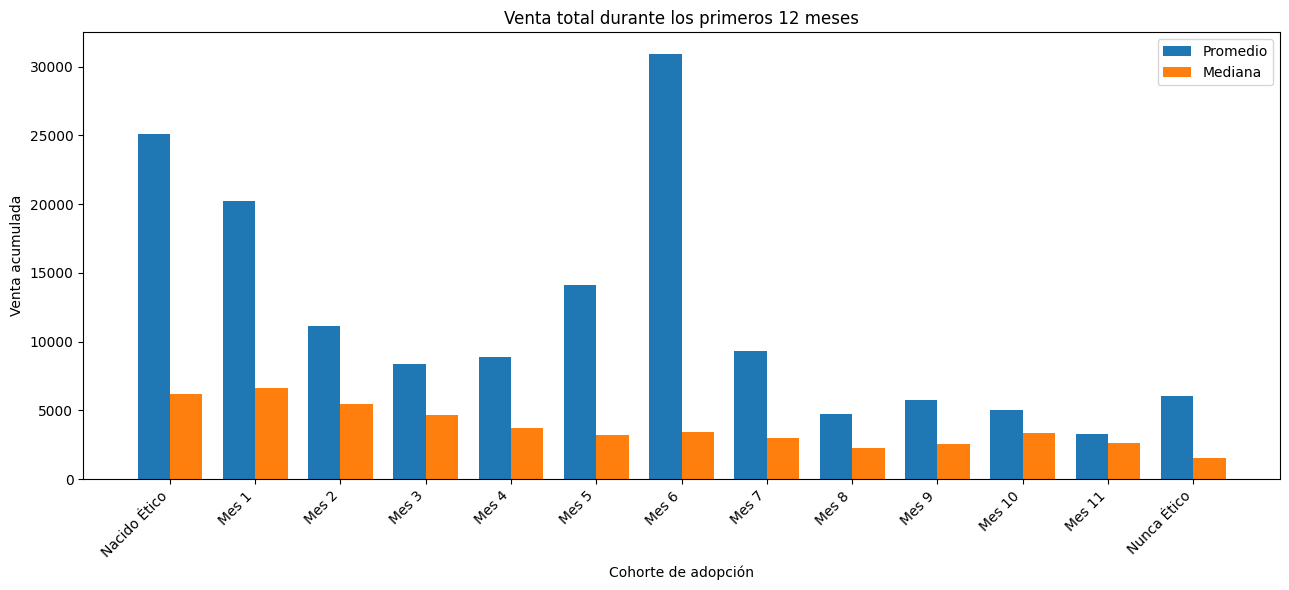

In [16]:
x = np.arange(len(df_resumen))
ancho = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - ancho / 2,
    df_resumen["venta_promedio"],
    width=ancho,
    label="Promedio"
)

plt.bar(
    x + ancho / 2,
    df_resumen["mediana_venta"],
    width=ancho,
    label="Mediana"
)

plt.title("Venta total durante los primeros 12 meses")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Venta acumulada")
plt.xticks(
    x,
    df_resumen["etiqueta_cohorte"],
    rotation=45,
    ha="right"
)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
df_resumen["brecha_promedio_mediana"] = (
    df_resumen["venta_promedio"]
    - df_resumen["mediana_venta"]
)

df_resumen["ratio_promedio_mediana"] = (
    df_resumen["venta_promedio"]
    / df_resumen["mediana_venta"].replace(0, np.nan)
)

display(
    df_resumen[
        [
            "etiqueta_cohorte",
            "clientes",
            "venta_promedio",
            "mediana_venta",
            "brecha_promedio_mediana",
            "ratio_promedio_mediana"
        ]
    ]
)

,etiqueta_cohorte,clientes,venta_promedio,mediana_venta,brecha_promedio_mediana,ratio_promedio_mediana
0,Nacido Ético,3893,"25,127.24","6,206.68","18,920.56",4.05
1,Mes 1,410,"20,252.80","6,602.30","13,650.50",3.07
2,Mes 2,274,"11,133.47","5,490.68","5,642.79",2.03
3,Mes 3,188,"8,367.94","4,644.94","3,723.00",1.80
4,Mes 4,122,"8,874.70","3,739.52","5,135.18",2.37
5,Mes 5,103,"14,119.10","3,246.35","10,872.75",4.35
6,Mes 6,72,"30,949.08","3,435.69","27,513.39",9.01
7,Mes 7,51,"9,329.14","3,002.63","6,326.51",3.11
8,Mes 8,48,"4,733.17","2,264.40","2,468.77",2.09
9,Mes 9,47,"5,779.37","2,525.76","3,253.61",2.29


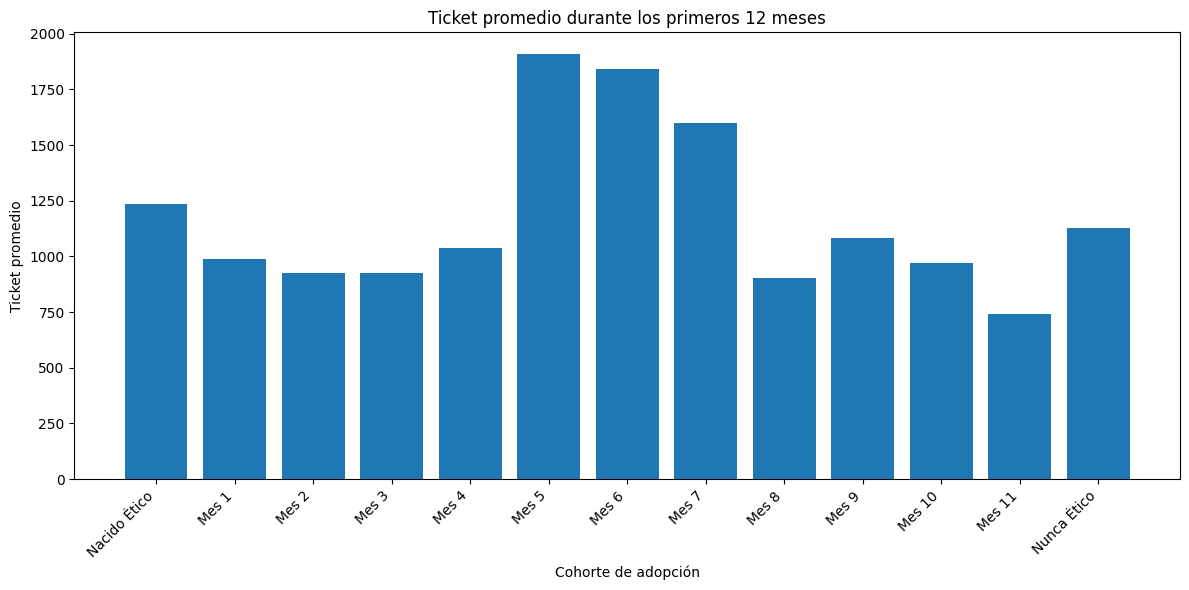

In [18]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["ticket_promedio"]
)

plt.title("Ticket promedio durante los primeros 12 meses")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Ticket promedio")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

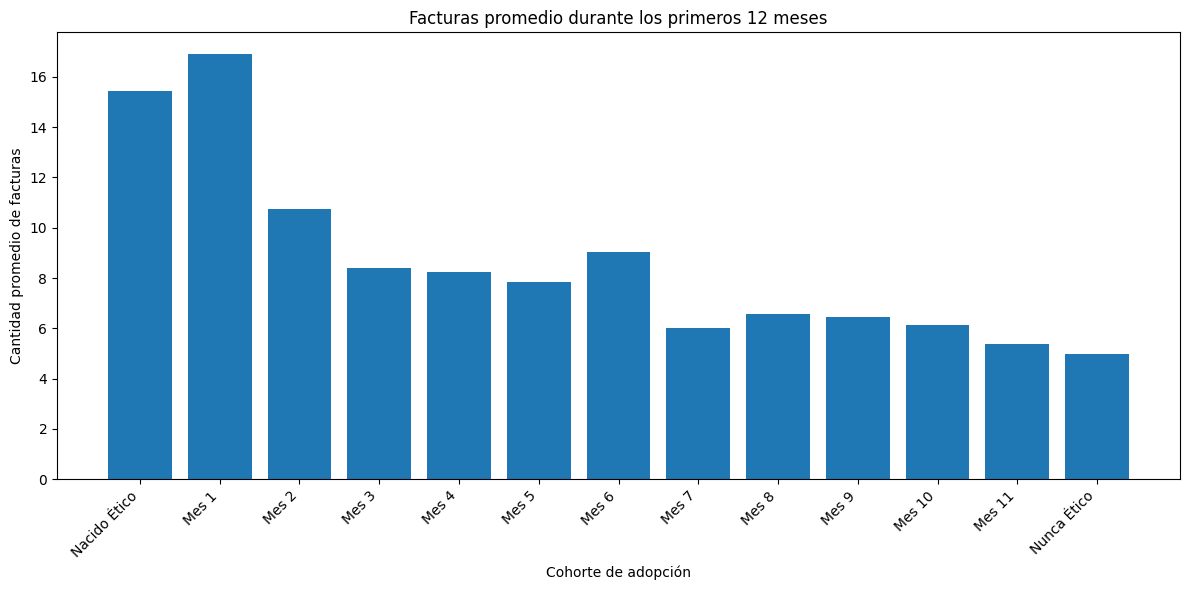

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["facturas_promedio"]
)

plt.title("Facturas promedio durante los primeros 12 meses")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Cantidad promedio de facturas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

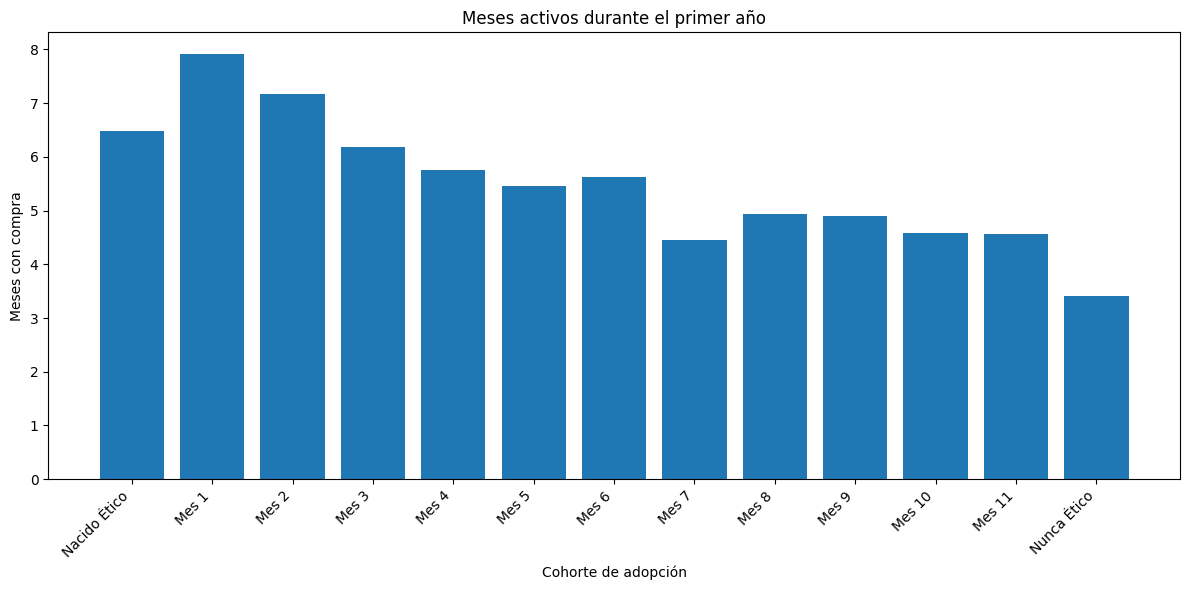

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["meses_activos_promedio"]
)

plt.title("Meses activos durante el primer año")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Meses con compra")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

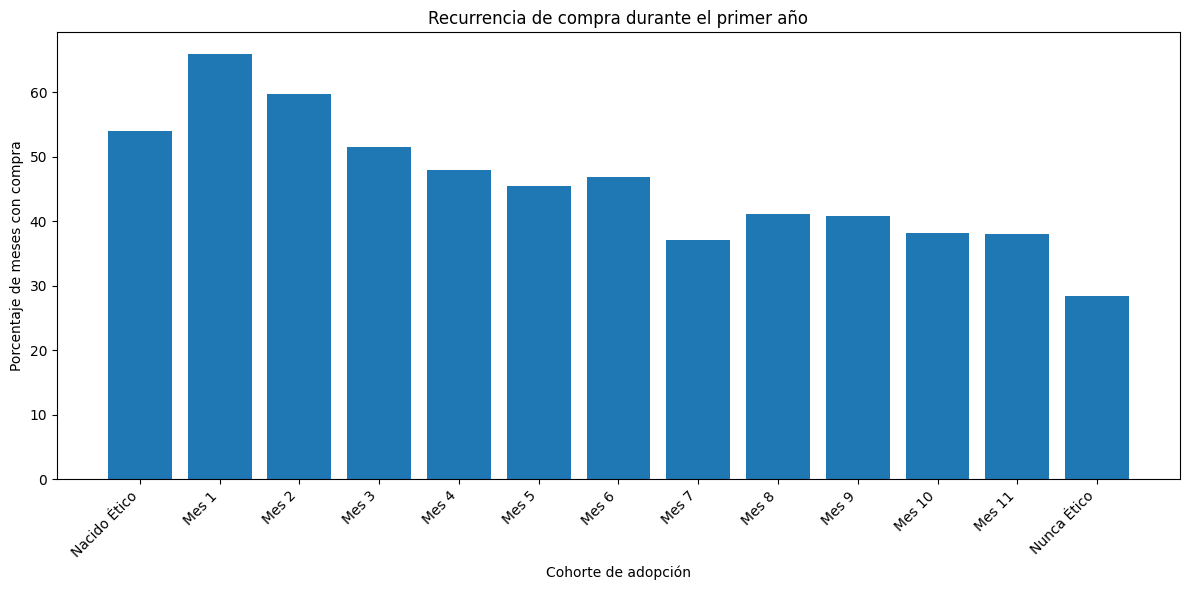

In [21]:
df_resumen["recurrencia_pct"] = (
    df_resumen["recurrencia_promedio"] * 100
)

plt.figure(figsize=(12, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["recurrencia_pct"]
)

plt.title("Recurrencia de compra durante el primer año")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Porcentaje de meses con compra")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

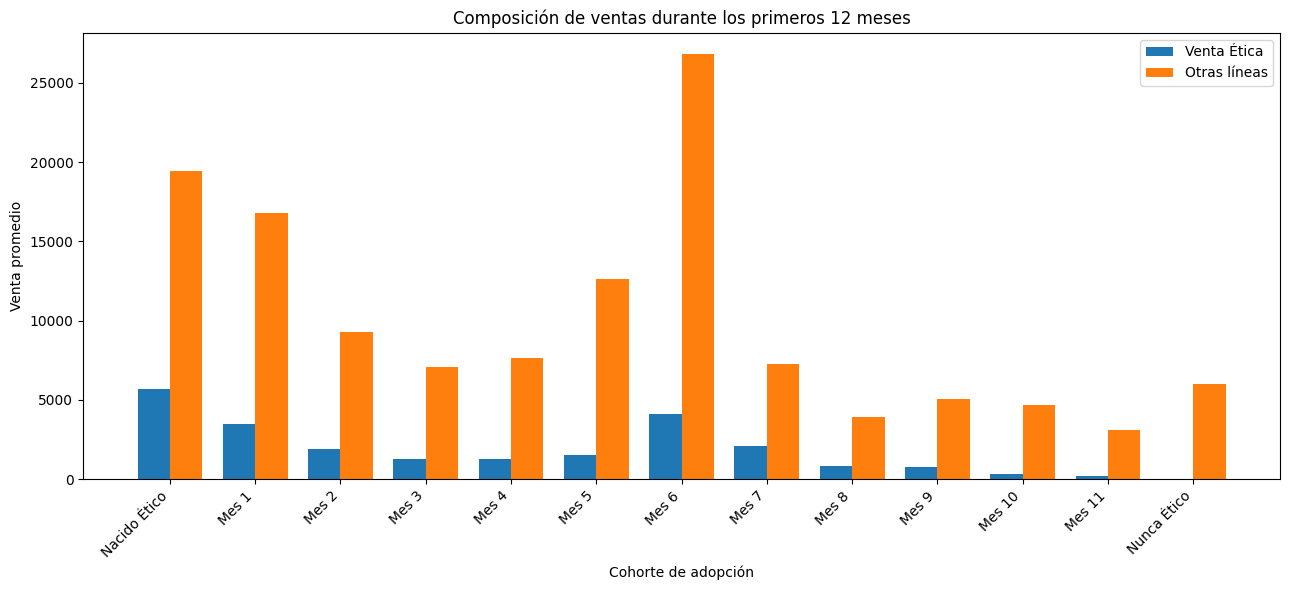

In [22]:
x = np.arange(len(df_resumen))
ancho = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - ancho / 2,
    df_resumen["venta_etica_promedio"],
    width=ancho,
    label="Venta Ética"
)

plt.bar(
    x + ancho / 2,
    df_resumen["venta_otras_promedio"],
    width=ancho,
    label="Otras líneas"
)

plt.title("Composición de ventas durante los primeros 12 meses")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Venta promedio")
plt.xticks(
    x,
    df_resumen["etiqueta_cohorte"],
    rotation=45,
    ha="right"
)
plt.legend()
plt.tight_layout()
plt.show()

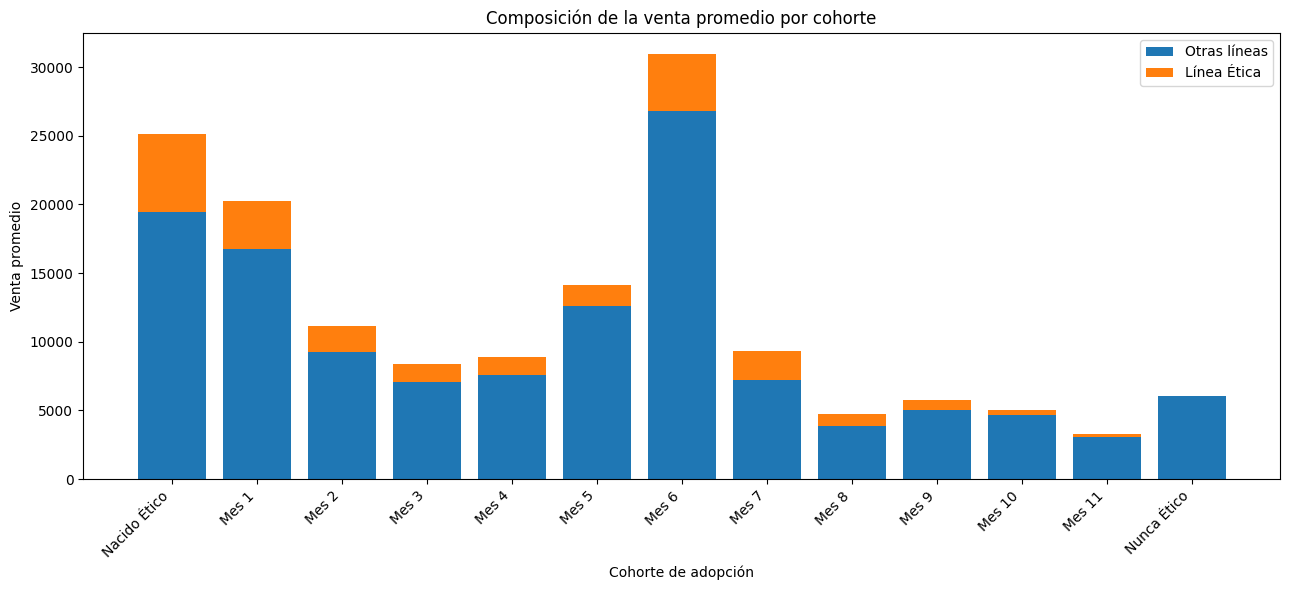

In [23]:
plt.figure(figsize=(13, 6))

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["venta_otras_promedio"],
    label="Otras líneas"
)

plt.bar(
    df_resumen["etiqueta_cohorte"],
    df_resumen["venta_etica_promedio"],
    bottom=df_resumen["venta_otras_promedio"],
    label="Línea Ética"
)

plt.title("Composición de la venta promedio por cohorte")
plt.xlabel("Cohorte de adopción")
plt.ylabel("Venta promedio")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
df_conversion = df_resumen[
    df_resumen["orden_cohorte"].between(0, 11)
].copy()

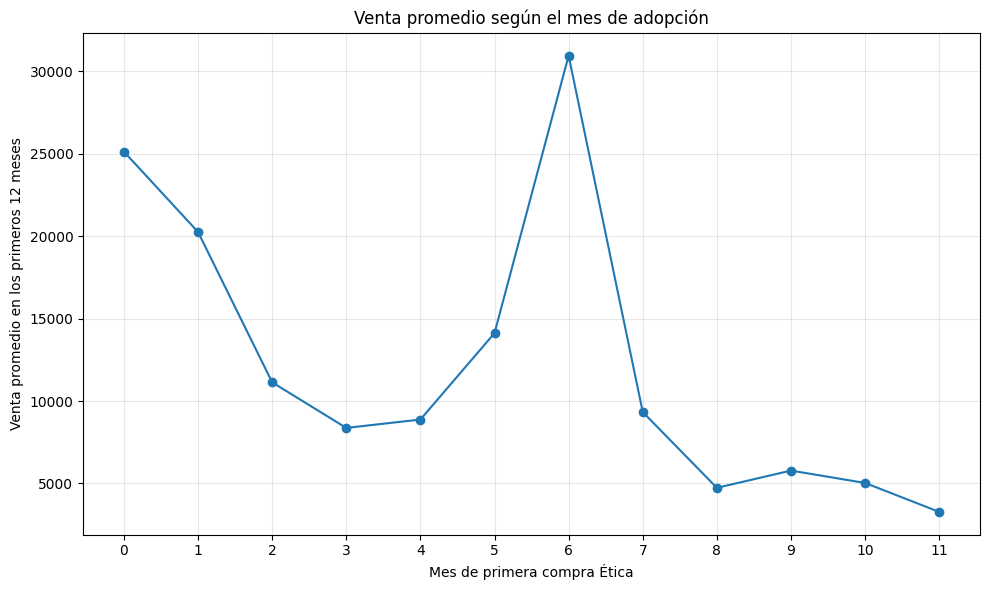

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_conversion["orden_cohorte"],
    df_conversion["venta_promedio"],
    marker="o"
)

plt.title("Venta promedio según el mes de adopción")
plt.xlabel("Mes de primera compra Ética")
plt.ylabel("Venta promedio en los primeros 12 meses")
plt.xticks(range(0, 12))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

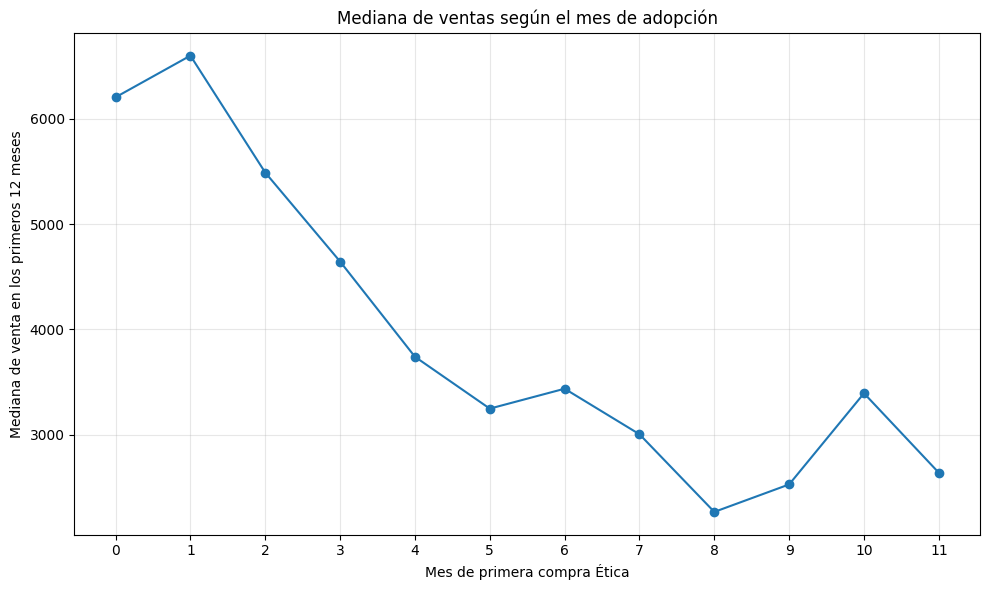

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_conversion["orden_cohorte"],
    df_conversion["mediana_venta"],
    marker="o"
)

plt.title("Mediana de ventas según el mes de adopción")
plt.xlabel("Mes de primera compra Ética")
plt.ylabel("Mediana de venta en los primeros 12 meses")
plt.xticks(range(0, 12))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
correlacion_promedio = (
    df_conversion["orden_cohorte"]
    .corr(df_conversion["venta_promedio"])
)

correlacion_mediana = (
    df_conversion["orden_cohorte"]
    .corr(df_conversion["mediana_venta"])
)

print(
    "Correlación mes de conversión - venta promedio:",
    round(correlacion_promedio, 3)
)

print(
    "Correlación mes de conversión - mediana de venta:",
    round(correlacion_mediana, 3)
)

Correlación mes de conversión - venta promedio: -0.595
Correlación mes de conversión - mediana de venta: -0.885


In [29]:
x = df_conversion["orden_cohorte"].to_numpy()
y = df_conversion["mediana_venta"].to_numpy()

pendiente, intercepto = np.polyfit(x, y, 1)

df_conversion["tendencia_mediana"] = (
    intercepto
    + pendiente * df_conversion["orden_cohorte"]
)

print("Pendiente estimada:", round(pendiente, 2))

Pendiente estimada: -359.58


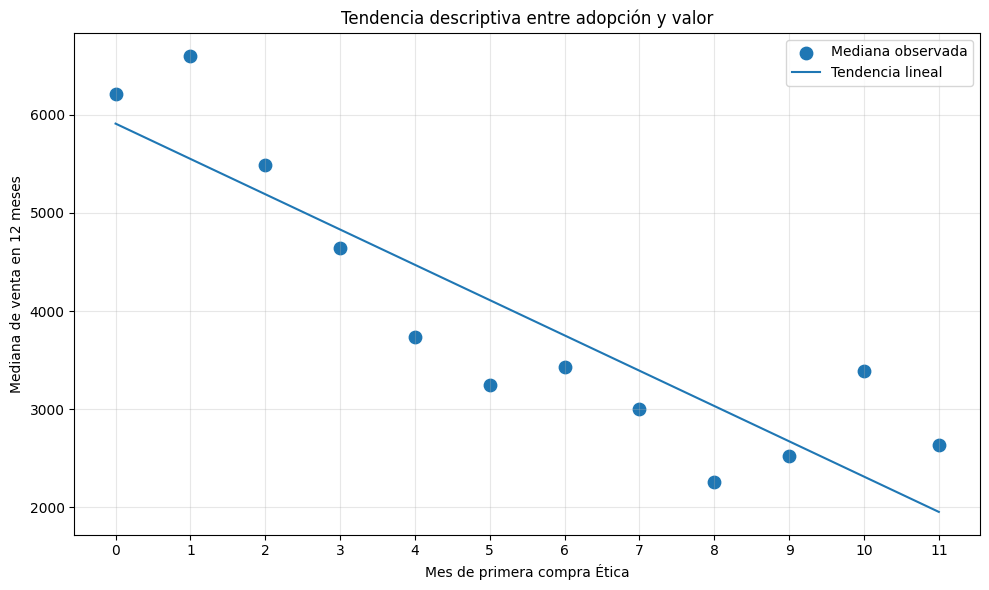

In [30]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_conversion["orden_cohorte"],
    df_conversion["mediana_venta"],
    s=80,
    label="Mediana observada"
)

plt.plot(
    df_conversion["orden_cohorte"],
    df_conversion["tendencia_mediana"],
    label="Tendencia lineal"
)

plt.title("Tendencia descriptiva entre adopción y valor")
plt.xlabel("Mes de primera compra Ética")
plt.ylabel("Mediana de venta en 12 meses")
plt.xticks(range(0, 12))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
nunca_etico = df_resumen[
    df_resumen["orden_cohorte"] == 99
]

if not nunca_etico.empty:
    venta_nunca = nunca_etico["venta_promedio"].iloc[0]
    mediana_nunca = nunca_etico["mediana_venta"].iloc[0]

    df_conversion["diferencia_venta_vs_nunca"] = (
        df_conversion["venta_promedio"]
        - venta_nunca
    )

    df_conversion["diferencia_mediana_vs_nunca"] = (
        df_conversion["mediana_venta"]
        - mediana_nunca
    )

    df_conversion["uplift_venta_vs_nunca_pct"] = (
        (
            df_conversion["venta_promedio"]
            / venta_nunca
        ) - 1
    ) * 100

    display(
        df_conversion[
            [
                "etiqueta_cohorte",
                "venta_promedio",
                "mediana_venta",
                "diferencia_venta_vs_nunca",
                "diferencia_mediana_vs_nunca",
                "uplift_venta_vs_nunca_pct"
            ]
        ]
    )

,etiqueta_cohorte,venta_promedio,mediana_venta,diferencia_venta_vs_nunca,diferencia_mediana_vs_nunca,uplift_venta_vs_nunca_pct
0,Nacido Ético,"25,127.24","6,206.68","19,092.58","4,633.98",316.38
1,Mes 1,"20,252.80","6,602.30","14,218.14","5,029.60",235.61
2,Mes 2,"11,133.47","5,490.68","5,098.81","3,917.98",84.49
3,Mes 3,"8,367.94","4,644.94","2,333.28","3,072.24",38.66
4,Mes 4,"8,874.70","3,739.52","2,840.04","2,166.82",47.06
5,Mes 5,"14,119.10","3,246.35","8,084.44","1,673.65",133.97
6,Mes 6,"30,949.08","3,435.69","24,914.43","1,862.99",412.86
7,Mes 7,"9,329.14","3,002.63","3,294.48","1,429.93",54.59
8,Mes 8,"4,733.17","2,264.40","-1,301.49",691.70,-21.57
9,Mes 9,"5,779.37","2,525.76",-255.28,953.06,-4.23


In [32]:
tabla_ejecutiva = df_resumen[
    [
        "etiqueta_cohorte",
        "clientes",
        "venta_promedio",
        "mediana_venta",
        "ticket_promedio",
        "facturas_promedio",
        "meses_activos_promedio",
        "recurrencia_pct"
    ]
].copy()

tabla_ejecutiva = tabla_ejecutiva.rename(
    columns={
        "etiqueta_cohorte": "Cohorte",
        "clientes": "Clientes",
        "venta_promedio": "Venta promedio 12M",
        "mediana_venta": "Mediana venta 12M",
        "ticket_promedio": "Ticket promedio",
        "facturas_promedio": "Facturas promedio",
        "meses_activos_promedio": "Meses activos",
        "recurrencia_pct": "Recurrencia %"
    }
)

display(tabla_ejecutiva)

,Cohorte,Clientes,Venta promedio 12M,Mediana venta 12M,Ticket promedio,Facturas promedio,Meses activos,Recurrencia %
0,Nacido Ético,3893,"25,127.24","6,206.68","1,236.69",15.42,6.49,54.06
1,Mes 1,410,"20,252.80","6,602.30",990.45,16.93,7.92,66.02
2,Mes 2,274,"11,133.47","5,490.68",927.37,10.74,7.16,59.70
3,Mes 3,188,"8,367.94","4,644.94",924.25,8.40,6.18,51.51
4,Mes 4,122,"8,874.70","3,739.52","1,038.75",8.25,5.75,47.95
5,Mes 5,103,"14,119.10","3,246.35","1,910.80",7.85,5.47,45.55
6,Mes 6,72,"30,949.08","3,435.69","1,841.63",9.04,5.62,46.88
7,Mes 7,51,"9,329.14","3,002.63","1,597.11",6.02,4.45,37.09
8,Mes 8,48,"4,733.17","2,264.40",902.92,6.56,4.94,41.15
9,Mes 9,47,"5,779.37","2,525.76","1,082.88",6.47,4.89,40.78


In [33]:
tabla_ejecutiva.to_csv(
    "tabla_ejecutiva_cohortes.csv",
    index=False,
    encoding="utf-8-sig"
)

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [34]:
ruta_clientes = "ca_cliente_metricas_12m.csv"

df = pd.read_csv(ruta_clientes)

print("Filas:", len(df))
print("Columnas:", len(df.columns))

display(df.head())

Filas: 6881
Columnas: 28


,codigo_cliente,fecha_inicio_cliente,mes_conversion,orden_cohorte,cohorte,ventana_12m_completa,venta_total_12m,venta_etica_12m,venta_otras_12m,participacion_etica_pct,descuento_total_12m,unidades_12m,facturas_12m,facturas_etica_12m,facturas_no_etica_12m,ticket_promedio_12m,ticket_maximo_12m,ticket_minimo_12m,meses_con_compra_12m,meses_con_compra_etica_12m,meses_con_compra_no_etica_12m,recurrencia_12m,venta_promedio_mes_activo,facturas_promedio_mes_activo,max_productos_distintos_mes,max_productos_etica_mes,max_productos_no_etica_mes,max_lineas_distintas_mes
0,C4507632010,2022-07-01,1.00,1,Convertido mes 1,1,"17,960.41","2,478.39","15,469.00",13.80,"3,042.79",328.00,26,10,25,690.79,"3,556.91",84.62,12,7,12,1.00,"1,496.70",2.00,10,3,9,4
1,C1765380017,2023-05-01,NaN,99,Nunca Etico,1,617.78,0.00,617.00,0.00,104.62,4.00,2,0,2,308.89,321.30,296.48,2,0,2,0.17,308.89,1.00,1,0,1,1
2,C5899292017,2022-08-01,0.00,0,Nacido Etico,1,"4,456.26",521.69,"3,932.00",11.71,"1,125.54",52.00,6,4,6,742.71,"2,001.80",292.31,6,4,6,0.50,742.71,1.00,5,2,4,3
3,C4008430016,2022-07-01,0.00,0,Nacido Etico,1,"23,176.67","6,099.51","17,072.00",26.32,"3,963.73",314.00,10,10,10,"2,317.67","3,648.83",727.64,8,8,8,0.67,"2,897.08",1.00,23,7,18,4
4,C5353259017,2025-04-01,6.00,6,Convertido mes 6,1,"5,375.10",237.03,"5,135.00",4.41,"1,591.12",74.00,7,1,6,767.87,"1,626.12",237.03,6,1,6,0.50,895.85,1.00,3,2,3,2


In [35]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['codigo_cliente', 'fecha_inicio_cliente', 'mes_conversion', 'orden_cohorte', 'cohorte', 'ventana_12m_completa', 'venta_total_12m', 'venta_etica_12m', 'venta_otras_12m', 'participacion_etica_pct', 'descuento_total_12m', 'unidades_12m', 'facturas_12m', 'facturas_etica_12m', 'facturas_no_etica_12m', 'ticket_promedio_12m', 'ticket_maximo_12m', 'ticket_minimo_12m', 'meses_con_compra_12m', 'meses_con_compra_etica_12m', 'meses_con_compra_no_etica_12m', 'recurrencia_12m', 'venta_promedio_mes_activo', 'facturas_promedio_mes_activo', 'max_productos_distintos_mes', 'max_productos_etica_mes', 'max_productos_no_etica_mes', 'max_lineas_distintas_mes']


In [36]:
print("Clientes únicos:", df["codigo_cliente"].nunique())
print("Filas totales:", len(df))
print(
    "Duplicados:",
    df["codigo_cliente"].duplicated().sum()
)

Clientes únicos: 6881
Filas totales: 6881
Duplicados: 0


In [37]:
if "ventana_12m_completa" in df.columns:
    df = df[
        df["ventana_12m_completa"] == 1
    ].copy()

In [38]:
columnas_numericas = [
    "orden_cohorte",
    "venta_total_12m",
    "venta_etica_12m",
    "venta_otras_12m",
    "ticket_promedio_12m",
    "facturas_12m",
    "meses_con_compra_12m",
    "recurrencia_12m"
]

for columna in columnas_numericas:
    if columna in df.columns:
        df[columna] = pd.to_numeric(
            df[columna],
            errors="coerce"
        )

In [39]:
display(
    df[columnas_numericas]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

orden_cohorte           0
venta_total_12m         0
venta_etica_12m         0
venta_otras_12m         0
ticket_promedio_12m     0
facturas_12m            0
meses_con_compra_12m    0
recurrencia_12m         0
dtype: int64

In [40]:
def etiqueta_cohorte(orden):
    if orden == 0:
        return "Nacido Ético"

    if 1 <= orden <= 11:
        return f"Mes {int(orden)}"

    if orden == 99:
        return "Nunca Ético"

    return "Sin clasificar"

In [41]:
df["etiqueta_cohorte"] = (
    df["orden_cohorte"]
    .apply(etiqueta_cohorte)
)

In [42]:
orden_etiquetas = (
    ["Nacido Ético"]
    + [f"Mes {mes}" for mes in range(1, 12)]
    + ["Nunca Ético"]
)

df["etiqueta_cohorte"] = pd.Categorical(
    df["etiqueta_cohorte"],
    categories=orden_etiquetas,
    ordered=True
)

In [43]:
display(
    df["venta_total_12m"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

count       6,881.00
mean       18,383.04
std       177,963.44
min            43.68
1%            203.85
5%            447.98
10%           755.12
25%         1,887.14
50%         4,564.70
75%        10,744.44
90%        23,258.59
95%        39,326.61
99%       161,681.28
max     9,021,633.19
Name: venta_total_12m, dtype: float64

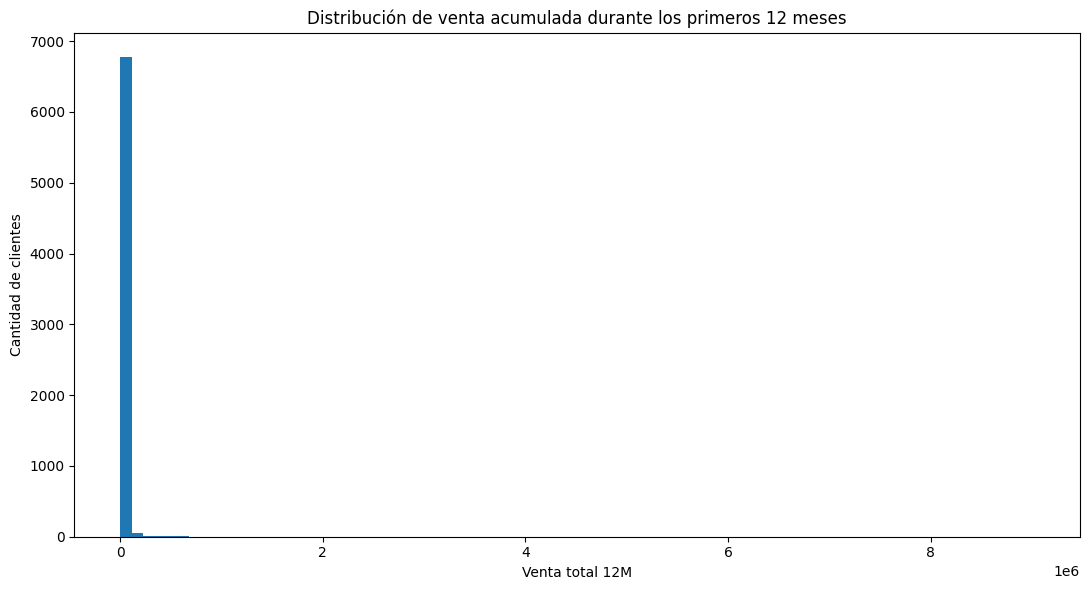

In [44]:
plt.figure(figsize=(11, 6))

plt.hist(
    df["venta_total_12m"].dropna(),
    bins=80
)

plt.title("Distribución de venta acumulada durante los primeros 12 meses")
plt.xlabel("Venta total 12M")
plt.ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

In [45]:
def percentil(serie, valor):
    return serie.quantile(valor)

In [46]:
tabla_percentiles = (
    df
    .groupby(
        "etiqueta_cohorte",
        observed=True
    )
    .agg(
        clientes=("codigo_cliente", "nunique"),

        promedio=(
            "venta_total_12m",
            "mean"
        ),

        p01=(
            "venta_total_12m",
            lambda x: percentil(x, 0.01)
        ),

        p05=(
            "venta_total_12m",
            lambda x: percentil(x, 0.05)
        ),

        p10=(
            "venta_total_12m",
            lambda x: percentil(x, 0.10)
        ),

        p25=(
            "venta_total_12m",
            lambda x: percentil(x, 0.25)
        ),

        p50=(
            "venta_total_12m",
            lambda x: percentil(x, 0.50)
        ),

        p75=(
            "venta_total_12m",
            lambda x: percentil(x, 0.75)
        ),

        p90=(
            "venta_total_12m",
            lambda x: percentil(x, 0.90)
        ),

        p95=(
            "venta_total_12m",
            lambda x: percentil(x, 0.95)
        ),

        p99=(
            "venta_total_12m",
            lambda x: percentil(x, 0.99)
        ),

        maximo=(
            "venta_total_12m",
            "max"
        )
    )
    .reset_index()
)

In [47]:
display(tabla_percentiles)

,etiqueta_cohorte,clientes,promedio,p01,p05,p10,p25,p50,p75,p90,p95,p99,maximo
0,Nacido Ético,3893,"25,127.24",369.34,832.70,"1,335.15","2,976.01","6,206.68","13,877.69","28,673.42","46,079.37","233,711.89","9,021,633.19"
1,Mes 1,410,"20,252.80",652.70,"1,153.52","1,695.16","3,346.22","6,602.30","13,306.34","24,998.02","43,398.14","282,702.03","1,649,790.56"
2,Mes 2,274,"11,133.47",793.12,"1,528.67","2,015.00","3,342.72","5,490.68","10,976.48","21,229.30","37,082.61","77,225.81","260,254.30"
3,Mes 3,188,"8,367.94",561.88,"1,218.07","1,609.00","2,470.82","4,644.94","8,310.69","14,561.37","23,787.96","60,616.62","171,474.50"
4,Mes 4,122,"8,874.70",421.92,811.87,"1,131.14","1,928.65","3,739.52","7,118.40","15,444.87","31,056.20","77,076.92","217,763.10"
5,Mes 5,103,"14,119.10",668.79,892.63,"1,433.96","2,007.03","3,246.35","5,623.98","13,962.20","30,261.84","183,845.07","551,410.38"
6,Mes 6,72,"30,949.08",802.59,"1,041.22","1,180.29","1,825.13","3,435.69","7,363.60","33,058.98","109,107.84","659,043.63","872,035.70"
7,Mes 7,51,"9,329.14",557.25,904.42,"1,035.62","1,763.73","3,002.63","5,946.77","19,608.33","25,314.81","114,058.30","138,580.61"
8,Mes 8,48,"4,733.17",670.32,"1,015.62","1,186.70","1,631.07","2,264.40","4,618.99","11,617.69","16,220.56","33,008.37","33,071.00"
9,Mes 9,47,"5,779.37",433.23,616.92,945.05,"1,418.83","2,525.76","4,083.30","7,796.73","17,547.27","60,158.55","69,507.20"


In [50]:
tabla_percentiles.to_excel("chorte_percentil.xlsx", index=False)

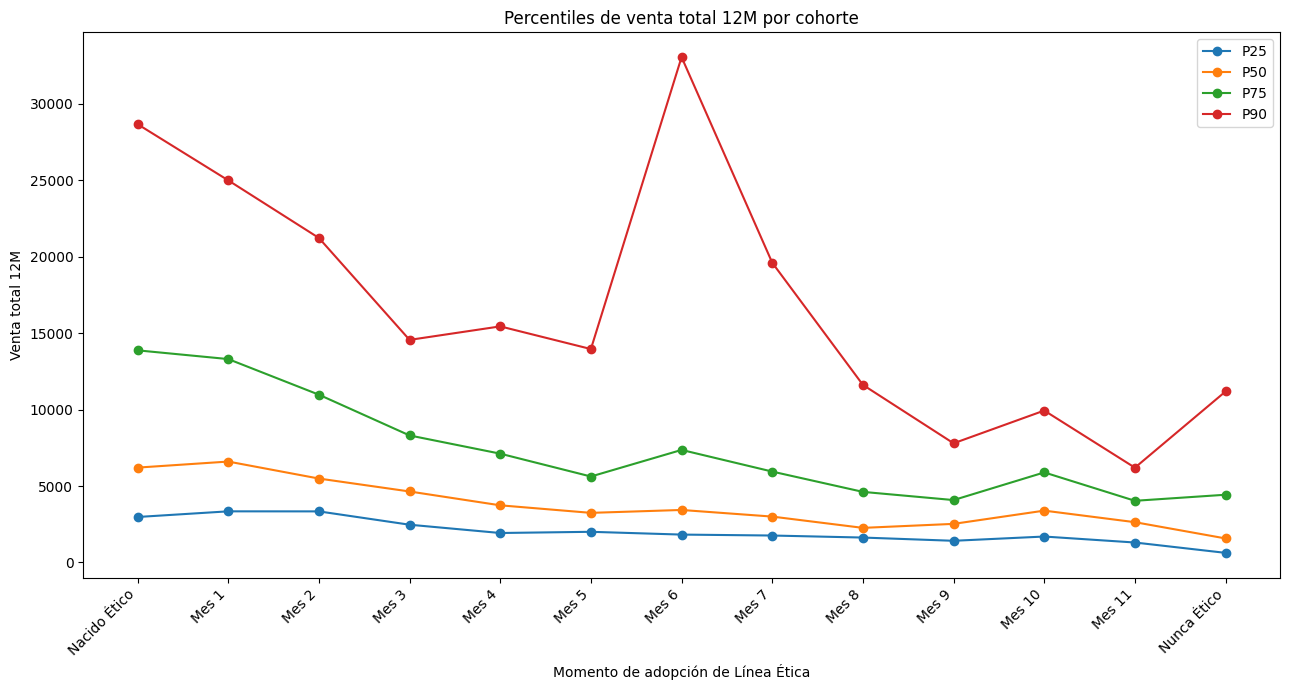

In [51]:
x = np.arange(len(tabla_percentiles))

plt.figure(figsize=(13, 7))

plt.plot(
    x,
    tabla_percentiles["p25"],
    marker="o",
    label="P25"
)

plt.plot(
    x,
    tabla_percentiles["p50"],
    marker="o",
    label="P50"
)

plt.plot(
    x,
    tabla_percentiles["p75"],
    marker="o",
    label="P75"
)

plt.plot(
    x,
    tabla_percentiles["p90"],
    marker="o",
    label="P90"
)

plt.xticks(
    x,
    tabla_percentiles["etiqueta_cohorte"],
    rotation=45,
    ha="right"
)

plt.title("Percentiles de venta total 12M por cohorte")
plt.xlabel("Momento de adopción de Línea Ética")
plt.ylabel("Venta total 12M")
plt.legend()
plt.tight_layout()
plt.show()

In [52]:
datos_boxplot = []

etiquetas_boxplot = []

for cohorte in orden_etiquetas:
    valores = (
        df.loc[
            df["etiqueta_cohorte"] == cohorte,
            "venta_total_12m"
        ]
        .dropna()
        .to_numpy()
    )

    if len(valores) > 0:
        datos_boxplot.append(valores)
        etiquetas_boxplot.append(cohorte)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_9892\4134951530.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


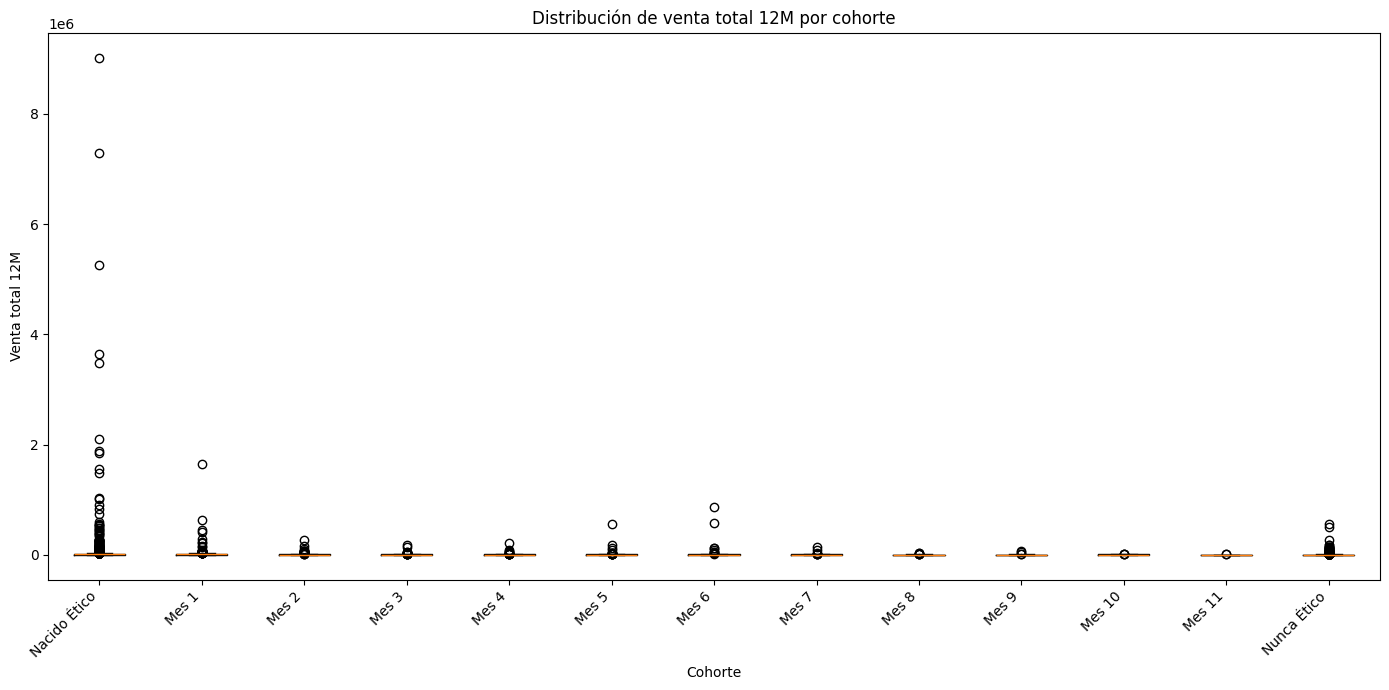

In [53]:
plt.figure(figsize=(14, 7))

plt.boxplot(
    datos_boxplot,
    labels=etiquetas_boxplot,
    showfliers=True
)

plt.title("Distribución de venta total 12M por cohorte")
plt.xlabel("Cohorte")
plt.ylabel("Venta total 12M")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_9892\3176493075.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


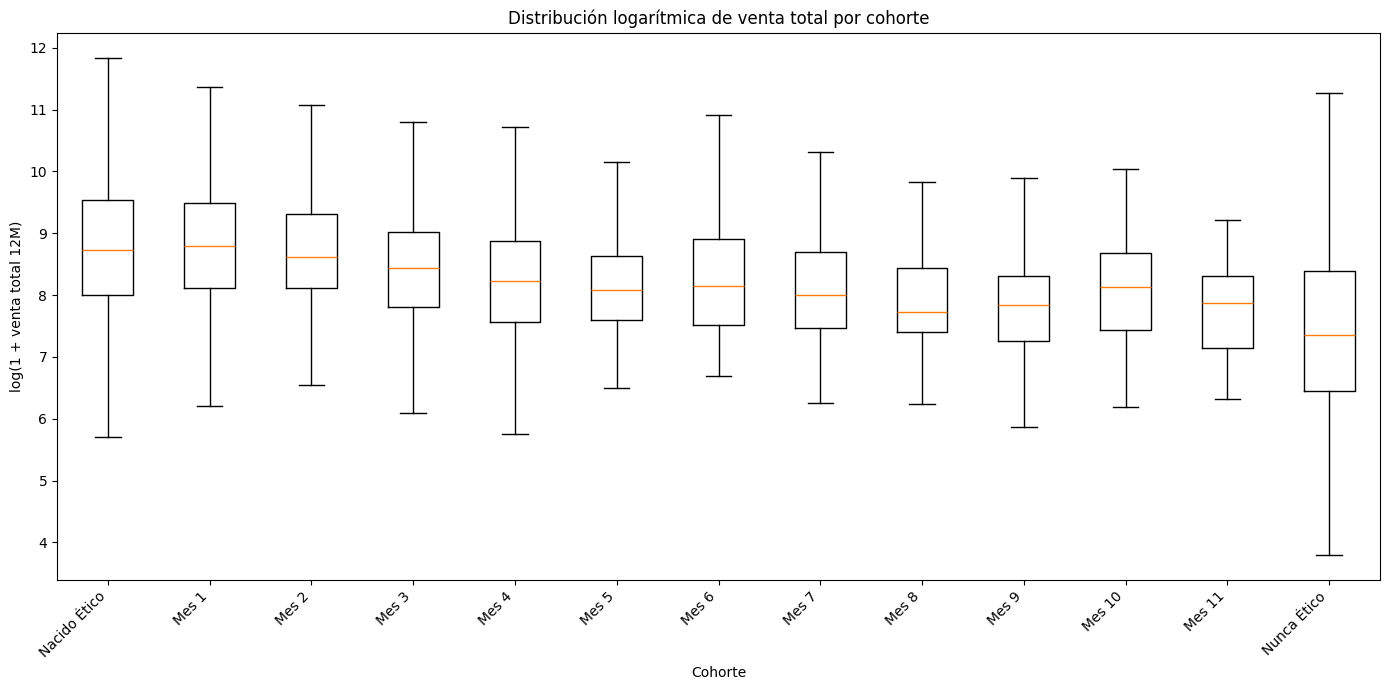

In [54]:
datos_log = [
    np.log1p(valores)
    for valores in datos_boxplot
]

plt.figure(figsize=(14, 7))

plt.boxplot(
    datos_log,
    labels=etiquetas_boxplot,
    showfliers=False
)

plt.title("Distribución logarítmica de venta total por cohorte")
plt.xlabel("Cohorte")
plt.ylabel("log(1 + venta total 12M)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [55]:
cortes_globales = {
    "p90": df["venta_total_12m"].quantile(0.90),
    "p95": df["venta_total_12m"].quantile(0.95),
    "p99": df["venta_total_12m"].quantile(0.99)
}

cortes_globales

{'p90': 23258.59, 'p95': 39326.61, 'p99': 161681.28399999937}

In [57]:
print("P90:", f'{cortes_globales["p90"]:,.2f}')
print("P95:", f'{cortes_globales["p95"]:,.2f}')
print("P99:", f'{cortes_globales["p99"]:,.2f}')

P90: 23,258.59
P95: 39,326.61
P99: 161,681.28


In [56]:
top_1 = (
    df[
        df["venta_total_12m"]
        >= cortes_globales["p99"]
    ]
    .sort_values(
        "venta_total_12m",
        ascending=False
    )
)

In [58]:
display(
    top_1[
        [
            "codigo_cliente",
            "etiqueta_cohorte",
            "venta_total_12m",
            "venta_etica_12m",
            "venta_otras_12m",
            "ticket_promedio_12m",
            "facturas_12m",
            "meses_con_compra_12m"
        ]
    ].head(30)
)

,codigo_cliente,etiqueta_cohorte,venta_total_12m,venta_etica_12m,venta_otras_12m,ticket_promedio_12m,facturas_12m,meses_con_compra_12m
2369,C1015447026,Nacido Ético,"9,021,633.19","2,510,515.06","6,510,931.00","18,992.91",475,12
6001,C4114218011,Nacido Ético,"7,284,341.82","214,003.74","7,070,044.00","10,743.87",678,12
4618,C502571022,Nacido Ético,"5,256,254.20","667,383.93","4,588,611.00","8,225.75",639,12
6727,C133795023,Nacido Ético,"3,641,486.21","1,034,246.98","2,607,061.00","11,204.57",325,12
6496,C1028435021,Nacido Ético,"3,485,942.09","441,711.69","3,044,208.00","63,380.77",55,12
3805,C3235791012,Nacido Ético,"2,098,173.63","429,302.68","1,668,812.00","13,536.60",155,12
1228,C150036024,Nacido Ético,"1,889,538.65","332,112.72","1,557,383.00","19,281.01",98,12
4534,C296812023,Nacido Ético,"1,839,811.72","61,208.80","1,778,549.00","12,515.73",147,12
344,C400618026,Mes 1,"1,649,790.56","224,914.41","1,424,840.00","15,863.37",104,12
6795,C1028627025,Nacido Ético,"1,551,147.38","314,894.43","1,235,936.00","2,291.21",677,12


In [59]:
venta_total_global = df["venta_total_12m"].sum()

In [60]:
concentracion = pd.DataFrame({
    "grupo": [
        "Top 1%",
        "Top 5%",
        "Top 10%"
    ],

    "venta": [
        df.loc[
            df["venta_total_12m"]
            >= df["venta_total_12m"].quantile(0.99),
            "venta_total_12m"
        ].sum(),

        df.loc[
            df["venta_total_12m"]
            >= df["venta_total_12m"].quantile(0.95),
            "venta_total_12m"
        ].sum(),

        df.loc[
            df["venta_total_12m"]
            >= df["venta_total_12m"].quantile(0.90),
            "venta_total_12m"
        ].sum()
    ]
})

In [61]:
concentracion["participacion_venta_pct"] = (
    concentracion["venta"]
    / venta_total_global
    * 100
)

display(concentracion)

,grupo,venta,participacion_venta_pct
0,Top 1%,"61,996,358.77",49.01
1,Top 5%,"80,927,086.02",63.98
2,Top 10%,"91,174,133.20",72.08


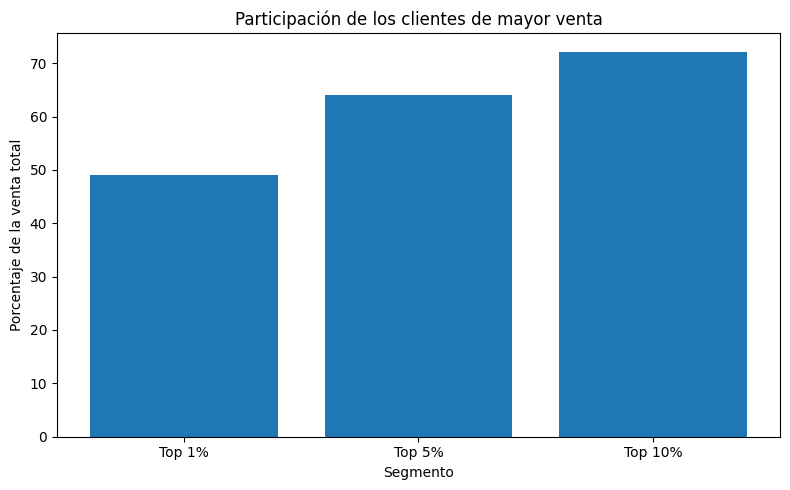

In [62]:
plt.figure(figsize=(8, 5))

plt.bar(
    concentracion["grupo"],
    concentracion["participacion_venta_pct"]
)

plt.title("Participación de los clientes de mayor venta")
plt.xlabel("Segmento")
plt.ylabel("Porcentaje de la venta total")
plt.tight_layout()
plt.show()

In [63]:
corte_99 = df["venta_total_12m"].quantile(0.99)
corte_95 = df["venta_total_12m"].quantile(0.95)
corte_90 = df["venta_total_12m"].quantile(0.90)

In [64]:
escenarios = {
    "Base completa": df.copy(),

    "Sin Top 1%": df[
        df["venta_total_12m"] < corte_99
    ].copy(),

    "Sin Top 5%": df[
        df["venta_total_12m"] < corte_95
    ].copy(),

    "Sin Top 10%": df[
        df["venta_total_12m"] < corte_90
    ].copy()
}

In [65]:
def resumir_escenario(base, nombre):
    resumen = (
        base
        .groupby(
            [
                "orden_cohorte",
                "etiqueta_cohorte"
            ],
            observed=True
        )
        .agg(
            clientes=(
                "codigo_cliente",
                "nunique"
            ),

            venta_promedio=(
                "venta_total_12m",
                "mean"
            ),

            mediana_venta=(
                "venta_total_12m",
                "median"
            )
        )
        .reset_index()
    )

    resumen["escenario"] = nombre

    return resumen

In [66]:
resultados_escenarios = pd.concat(
    [
        resumir_escenario(base, nombre)
        for nombre, base in escenarios.items()
    ],
    ignore_index=True
)

In [67]:
display(resultados_escenarios.head(20))

,orden_cohorte,etiqueta_cohorte,clientes,venta_promedio,mediana_venta,escenario
0,0,Nacido Ético,3893,"25,127.24","6,206.68",Base completa
1,1,Mes 1,410,"20,252.80","6,602.30",Base completa
2,2,Mes 2,274,"11,133.47","5,490.68",Base completa
3,3,Mes 3,188,"8,367.94","4,644.94",Base completa
4,4,Mes 4,122,"8,874.70","3,739.52",Base completa
5,5,Mes 5,103,"14,119.10","3,246.35",Base completa
6,6,Mes 6,72,"30,949.08","3,435.69",Base completa
7,7,Mes 7,51,"9,329.14","3,002.63",Base completa
8,8,Mes 8,48,"4,733.17","2,264.40",Base completa
9,9,Mes 9,47,"5,779.37","2,525.76",Base completa


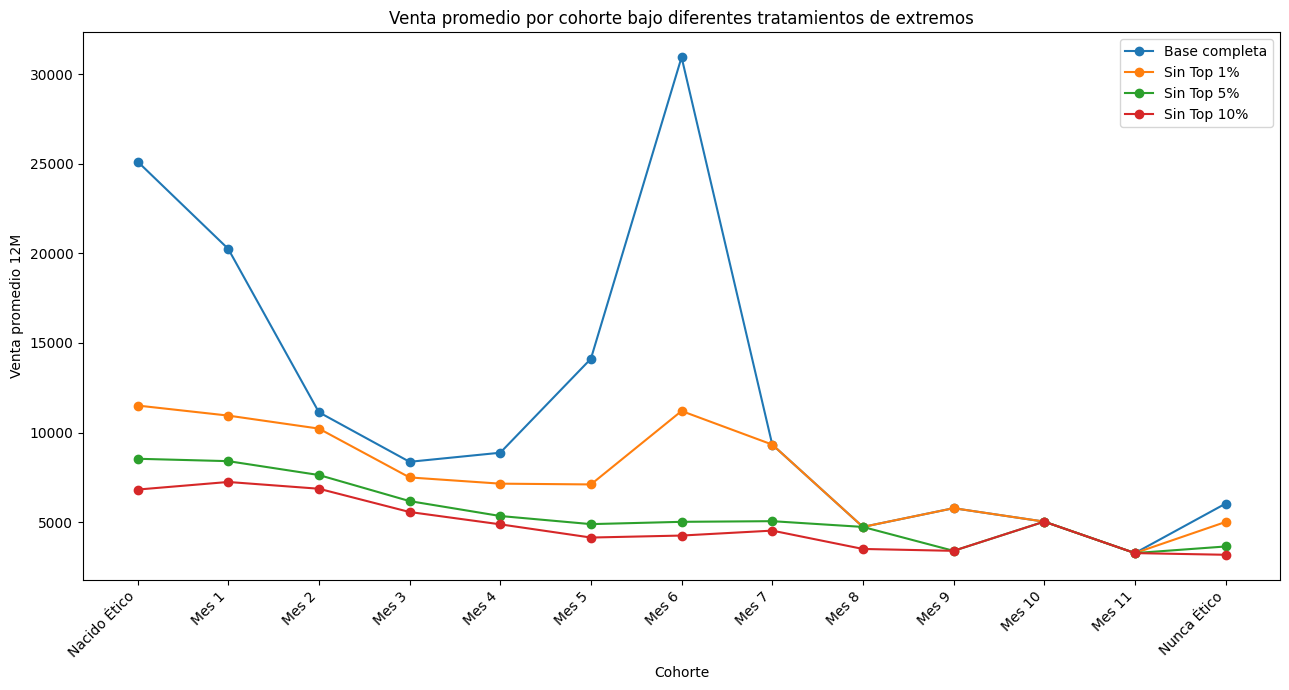

In [68]:
plt.figure(figsize=(13, 7))

for escenario in resultados_escenarios["escenario"].unique():

    datos = (
        resultados_escenarios[
            resultados_escenarios["escenario"]
            == escenario
        ]
        .sort_values("orden_cohorte")
    )

    plt.plot(
        datos["etiqueta_cohorte"],
        datos["venta_promedio"],
        marker="o",
        label=escenario
    )

plt.title("Venta promedio por cohorte bajo diferentes tratamientos de extremos")
plt.xlabel("Cohorte")
plt.ylabel("Venta promedio 12M")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

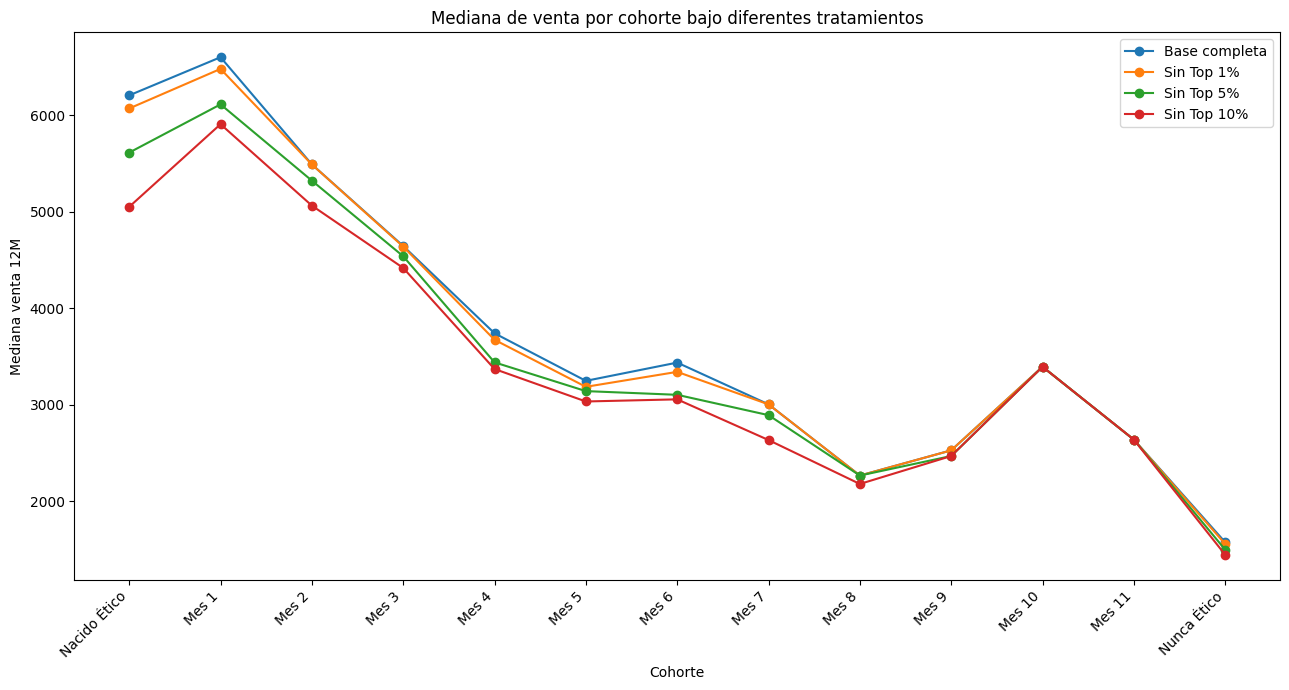

In [69]:
plt.figure(figsize=(13, 7))

for escenario in resultados_escenarios["escenario"].unique():

    datos = (
        resultados_escenarios[
            resultados_escenarios["escenario"]
            == escenario
        ]
        .sort_values("orden_cohorte")
    )

    plt.plot(
        datos["etiqueta_cohorte"],
        datos["mediana_venta"],
        marker="o",
        label=escenario
    )

plt.title("Mediana de venta por cohorte bajo diferentes tratamientos")
plt.xlabel("Cohorte")
plt.ylabel("Mediana venta 12M")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [69]:
limite_p99 = df["venta_total_12m"].quantile(0.99)

df["venta_total_winsor_p99"] = (
    df["venta_total_12m"]
    .clip(upper=limite_p99)
)

In [70]:
resumen_winsor = (
    df
    .groupby(
        [
            "orden_cohorte",
            "etiqueta_cohorte"
        ],
        observed=True
    )
    .agg(
        clientes=(
            "codigo_cliente",
            "nunique"
        ),

        promedio_original=(
            "venta_total_12m",
            "mean"
        ),

        promedio_winsorizado=(
            "venta_total_winsor_p99",
            "mean"
        ),

        mediana=(
            "venta_total_12m",
            "median"
        )
    )
    .reset_index()
    .sort_values("orden_cohorte")
)

In [71]:
display(resumen_winsor)

,orden_cohorte,etiqueta_cohorte,clientes,promedio_original,promedio_winsorizado,mediana
0,0,Nacido Ético,3893,"25,127.24","13,437.04","6,206.68"
1,1,Mes 1,410,"20,252.80","13,520.75","6,602.30"
2,2,Mes 2,274,"11,133.47","10,773.71","5,490.68"
3,3,Mes 3,188,"8,367.94","8,315.85","4,644.94"
4,4,Mes 4,122,"8,874.70","8,415.01","3,739.52"
5,5,Mes 5,103,"14,119.10","10,106.44","3,246.35"
6,6,Mes 6,72,"30,949.08","15,383.53","3,435.69"
7,7,Mes 7,51,"9,329.14","9,329.14","3,002.63"
8,8,Mes 8,48,"4,733.17","4,733.17","2,264.40"
9,9,Mes 9,47,"5,779.37","5,779.37","2,525.76"


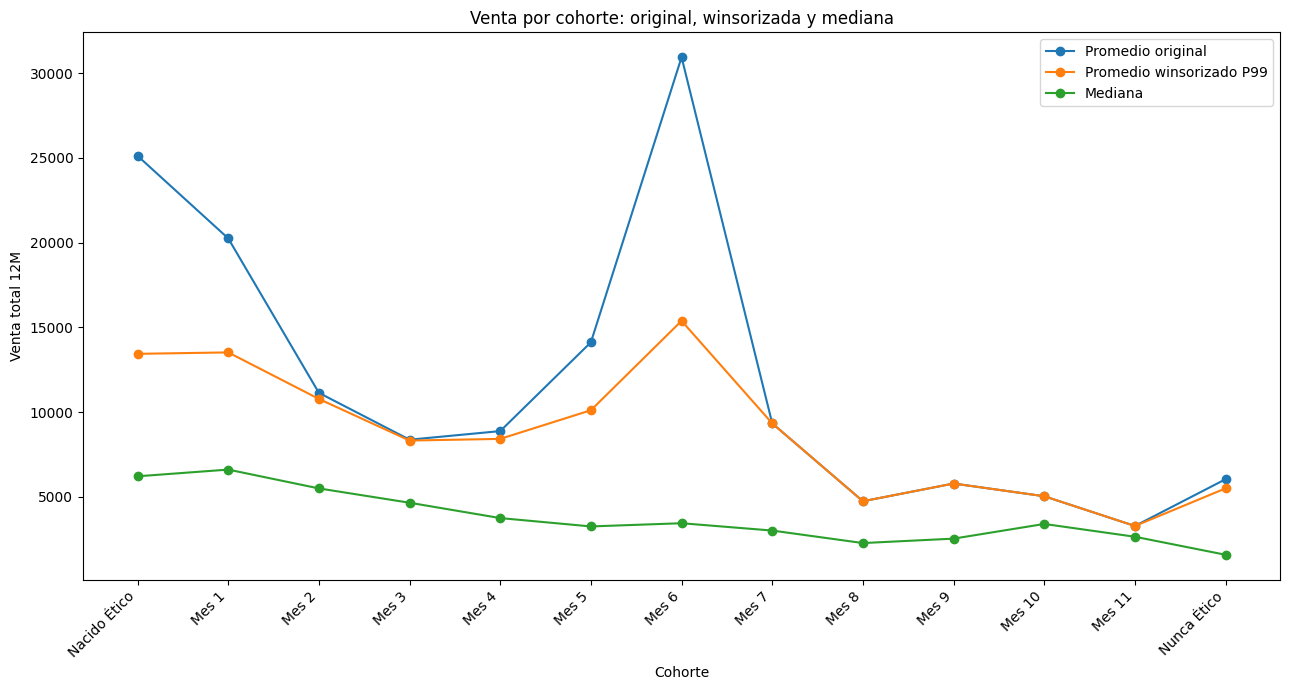

In [72]:
plt.figure(figsize=(13, 7))

plt.plot(
    resumen_winsor["etiqueta_cohorte"],
    resumen_winsor["promedio_original"],
    marker="o",
    label="Promedio original"
)

plt.plot(
    resumen_winsor["etiqueta_cohorte"],
    resumen_winsor["promedio_winsorizado"],
    marker="o",
    label="Promedio winsorizado P99"
)

plt.plot(
    resumen_winsor["etiqueta_cohorte"],
    resumen_winsor["mediana"],
    marker="o",
    label="Mediana"
)

plt.title("Venta por cohorte: original, winsorizada y mediana")
plt.xlabel("Cohorte")
plt.ylabel("Venta total 12M")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [73]:
conversiones = resumen_winsor[
    resumen_winsor["orden_cohorte"]
    .between(0, 11)
].copy()

In [74]:
correlaciones = pd.Series({
    "Promedio original": (
        conversiones["orden_cohorte"]
        .corr(conversiones["promedio_original"])
    ),

    "Promedio winsorizado": (
        conversiones["orden_cohorte"]
        .corr(conversiones["promedio_winsorizado"])
    ),

    "Mediana": (
        conversiones["orden_cohorte"]
        .corr(conversiones["mediana"])
    )
})

In [75]:
display(
    correlaciones
    .to_frame("correlacion_mes_conversion")
)

,correlacion_mes_conversion
Promedio original,-0.59
Promedio winsorizado,-0.76
Mediana,-0.89


In [76]:
def calcular_pendiente(df_base, columna_y):
    x = df_base["orden_cohorte"].to_numpy()
    y = df_base[columna_y].to_numpy()

    pendiente, intercepto = np.polyfit(
        x,
        y,
        1
    )

    return pendiente, intercepto

In [77]:
metricas_tendencia = []

for columna in [
    "promedio_original",
    "promedio_winsorizado",
    "mediana"
]:
    pendiente, intercepto = calcular_pendiente(
        conversiones,
        columna
    )

    metricas_tendencia.append({
        "metrica": columna,
        "pendiente_por_mes": pendiente,
        "intercepto": intercepto
    })

In [78]:
tabla_tendencias = pd.DataFrame(
    metricas_tendencia
)

display(tabla_tendencias)

,metrica,pendiente_por_mes,intercepto
0,promedio_original,"-1,450.62","20,225.68"
1,promedio_winsorizado,-815.01,"13,490.47"
2,mediana,-359.58,"5,910.00"


In [79]:
corte_top_1 = df["venta_total_12m"].quantile(0.99)

df["es_top_1_global"] = (
    df["venta_total_12m"]
    >= corte_top_1
).astype(int)

In [80]:
top_por_cohorte = (
    df
    .groupby(
        [
            "orden_cohorte",
            "etiqueta_cohorte"
        ],
        observed=True
    )
    .agg(
        clientes=(
            "codigo_cliente",
            "nunique"
        ),

        clientes_top_1=(
            "es_top_1_global",
            "sum"
        ),

        venta_total=(
            "venta_total_12m",
            "sum"
        ),

        venta_top_1=(
            "venta_total_12m",
            lambda x: x[
                x >= corte_top_1
            ].sum()
        )
    )
    .reset_index()
)

In [81]:
top_por_cohorte["clientes_top_1_pct"] = (
    top_por_cohorte["clientes_top_1"]
    / top_por_cohorte["clientes"]
    * 100
)

top_por_cohorte["venta_top_1_pct"] = (
    top_por_cohorte["venta_top_1"]
    / top_por_cohorte["venta_total"]
    * 100
)

In [82]:
display(top_por_cohorte)

,orden_cohorte,etiqueta_cohorte,clientes,clientes_top_1,venta_total,venta_top_1,clientes_top_1_pct,venta_top_1_pct
0,0,Nacido Ético,3893,50,"97,820,328.92","53,593,998.78",1.28,54.79
1,1,Mes 1,410,7,"8,303,648.88","3,891,909.48",1.71,46.87
2,2,Mes 2,274,1,"3,050,570.70","260,254.30",0.36,8.53
3,3,Mes 3,188,1,"1,573,172.51","171,474.50",0.53,10.90
4,4,Mes 4,122,1,"1,082,712.82","217,763.10",0.82,20.11
5,5,Mes 5,103,2,"1,454,267.60","736,667.30",1.94,50.66
6,6,Mes 6,72,2,"2,228,334.08","1,444,082.57",2.78,64.81
7,7,Mes 7,51,0,"475,785.92",0.00,0.00,0.00
8,8,Mes 8,48,0,"227,192.27",0.00,0.00,0.00
9,9,Mes 9,47,0,"271,630.56",0.00,0.00,0.00


In [84]:
resultados_escenarios.to_csv(
    "outputs_sensibilidad_outliers_cohortes.csv",
    index=False,
    encoding="utf-8-sig"
)

In [85]:
resumen_winsor.to_csv(
    "outputs_resumen_cohortes_winsorizado.csv",
    index=False,
    encoding="utf-8-sig"
)

In [86]:
top_por_cohorte.to_csv(
    "outputs_concentracion_top_1_por_cohorte.csv",
    index=False,
    encoding="utf-8-sig"
)

In [88]:
tabla_tendencias.to_csv(
    "outputs_tendencias_adopcion_venta.csv",
    index=False,
    encoding="utf-8-sig"
)

In [89]:
def clasificar_ventana_adopcion(orden):
    if orden == 0:
        return "Adopción inmediata"

    if 1 <= orden <= 2:
        return "Adopción temprana"

    if 3 <= orden <= 5:
        return "Adopción media"

    if 6 <= orden <= 11:
        return "Adopción tardía"

    if orden == 99:
        return "Nunca Ético"

    return "Sin clasificar"

In [90]:
df["ventana_adopcion"] = (
    df["orden_cohorte"]
    .apply(clasificar_ventana_adopcion)
)

In [91]:
orden_ventanas = [
    "Adopción inmediata",
    "Adopción temprana",
    "Adopción media",
    "Adopción tardía",
    "Nunca Ético"
]

In [92]:
df["ventana_adopcion"] = pd.Categorical(
    df["ventana_adopcion"],
    categories=orden_ventanas,
    ordered=True
)

In [93]:
display(
    df[
        [
            "codigo_cliente",
            "orden_cohorte",
            "ventana_adopcion"
        ]
    ].head(20)
)

,codigo_cliente,orden_cohorte,ventana_adopcion
0,C4507632010,1,Adopción temprana
1,C1765380017,99,Nunca Ético
2,C5899292017,0,Adopción inmediata
3,C4008430016,0,Adopción inmediata
4,C5353259017,6,Adopción tardía
5,C4820313,99,Nunca Ético
6,C4742506015,0,Adopción inmediata
7,C7282330010,0,Adopción inmediata
8,C10571718014,0,Adopción inmediata
9,C4928693014,0,Adopción inmediata


In [94]:
resumen_ventanas = (
    df
    .groupby(
        "ventana_adopcion",
        observed=True
    )
    .agg(
        clientes=(
            "codigo_cliente",
            "nunique"
        ),

        venta_promedio=(
            "venta_total_12m",
            "mean"
        ),

        mediana_venta=(
            "venta_total_12m",
            "median"
        ),

        venta_etica_promedio=(
            "venta_etica_12m",
            "mean"
        ),

        venta_otras_promedio=(
            "venta_otras_12m",
            "mean"
        ),

        ticket_promedio=(
            "ticket_promedio_12m",
            "mean"
        ),

        facturas_promedio=(
            "facturas_12m",
            "mean"
        ),

        meses_activos_promedio=(
            "meses_con_compra_12m",
            "mean"
        ),

        recurrencia_promedio=(
            "recurrencia_12m",
            "mean"
        )
    )
    .reset_index()
)

In [95]:
resumen_ventanas["recurrencia_pct"] = (
    resumen_ventanas["recurrencia_promedio"]
    * 100
)

In [96]:
display(resumen_ventanas)

,ventana_adopcion,clientes,venta_promedio,mediana_venta,venta_etica_promedio,venta_otras_promedio,ticket_promedio,facturas_promedio,meses_activos_promedio,recurrencia_promedio,recurrencia_pct
0,Adopción inmediata,3893,"25,127.24","6,206.68","5,706.94","19,413.57","1,236.69",15.42,6.49,0.54,54.06
1,Adopción temprana,684,"16,599.74","6,115.24","2,828.72","13,764.44",965.18,14.45,7.62,0.63,63.49
2,Adopción media,413,"9,951.94","3,890.24","1,337.15","8,611.08","1,204.11",8.22,5.88,0.49,48.97
3,Adopción tardía,276,"12,547.09","2,726.48","1,795.12","10,748.89","1,305.74",6.96,4.94,0.41,41.18
4,Nunca Ético,1615,"6,034.66","1,572.70",0.00,"6,032.39","1,126.96",4.96,3.42,0.28,28.48


In [97]:
percentiles_ventanas = (
    df
    .groupby(
        "ventana_adopcion",
        observed=True
    )["venta_total_12m"]
    .quantile(
        [
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .unstack()
    .reset_index()
)

In [98]:
percentiles_ventanas = percentiles_ventanas.rename(
    columns={
        0.25: "p25",
        0.50: "p50",
        0.75: "p75",
        0.90: "p90",
        0.95: "p95",
        0.99: "p99"
    }
)

In [99]:
resumen_ventanas = resumen_ventanas.merge(
    percentiles_ventanas,
    on="ventana_adopcion",
    how="left"
)

In [100]:
display(resumen_ventanas)

,ventana_adopcion,clientes,venta_promedio,mediana_venta,venta_etica_promedio,venta_otras_promedio,ticket_promedio,facturas_promedio,meses_activos_promedio,recurrencia_promedio,recurrencia_pct,p25,p50,p75,p90,p95,p99
0,Adopción inmediata,3893,"25,127.24","6,206.68","5,706.94","19,413.57","1,236.69",15.42,6.49,0.54,54.06,"2,976.01","6,206.68","13,877.69","28,673.42","46,079.37","233,711.89"
1,Adopción temprana,684,"16,599.74","6,115.24","2,828.72","13,764.44",965.18,14.45,7.62,0.63,63.49,"3,340.83","6,115.24","11,944.28","22,977.92","41,698.20","218,173.43"
2,Adopción media,413,"9,951.94","3,890.24","1,337.15","8,611.08","1,204.11",8.22,5.88,0.49,48.97,"2,246.90","3,890.24","7,497.98","15,030.71","27,964.63","135,301.92"
3,Adopción tardía,276,"12,547.09","2,726.48","1,795.12","10,748.89","1,305.74",6.96,4.94,0.41,41.18,"1,638.94","2,726.48","5,860.46","12,997.65","30,995.67","130,476.40"
4,Nunca Ético,1615,"6,034.66","1,572.70",0.00,"6,032.39","1,126.96",4.96,3.42,0.28,28.48,629.05,"1,572.70","4,432.20","11,190.05","19,903.51","78,372.83"


In [101]:
limite_p99 = df["venta_total_12m"].quantile(0.99)

df["venta_total_winsor_p99"] = (
    df["venta_total_12m"]
    .clip(upper=limite_p99)
)

In [102]:
winsor_ventanas = (
    df
    .groupby(
        "ventana_adopcion",
        observed=True
    )
    .agg(
        promedio_winsorizado=(
            "venta_total_winsor_p99",
            "mean"
        )
    )
    .reset_index()
)

In [103]:
resumen_ventanas = resumen_ventanas.merge(
    winsor_ventanas,
    on="ventana_adopcion",
    how="left"
)

In [104]:
columnas_finales = [
    "ventana_adopcion",
    "clientes",
    "venta_promedio",
    "promedio_winsorizado",
    "mediana_venta",
    "p25",
    "p50",
    "p75",
    "p90",
    "p95",
    "p99",
    "venta_etica_promedio",
    "venta_otras_promedio",
    "ticket_promedio",
    "facturas_promedio",
    "meses_activos_promedio",
    "recurrencia_pct"
]

In [107]:
resumen_ventanas = resumen_ventanas[
    columnas_finales
]

In [109]:
resumen_ventanas["participacion_clientes_pct"] = (
    resumen_ventanas["clientes"]
    / resumen_ventanas["clientes"].sum()
    * 100
)

In [110]:
display(
    resumen_ventanas[
        [
            "ventana_adopcion",
            "clientes",
            "participacion_clientes_pct"
        ]
    ]
)

,ventana_adopcion,clientes,participacion_clientes_pct
0,Adopción inmediata,3893,56.58
1,Adopción temprana,684,9.94
2,Adopción media,413,6.00
3,Adopción tardía,276,4.01
4,Nunca Ético,1615,23.47


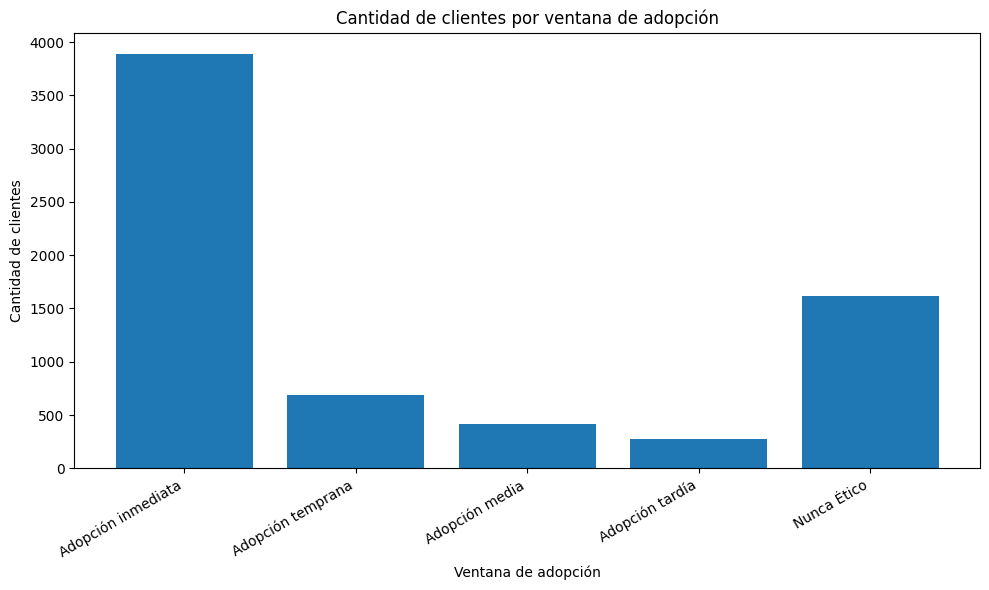

In [111]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumen_ventanas["ventana_adopcion"],
    resumen_ventanas["clientes"]
)

plt.title("Cantidad de clientes por ventana de adopción")
plt.xlabel("Ventana de adopción")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

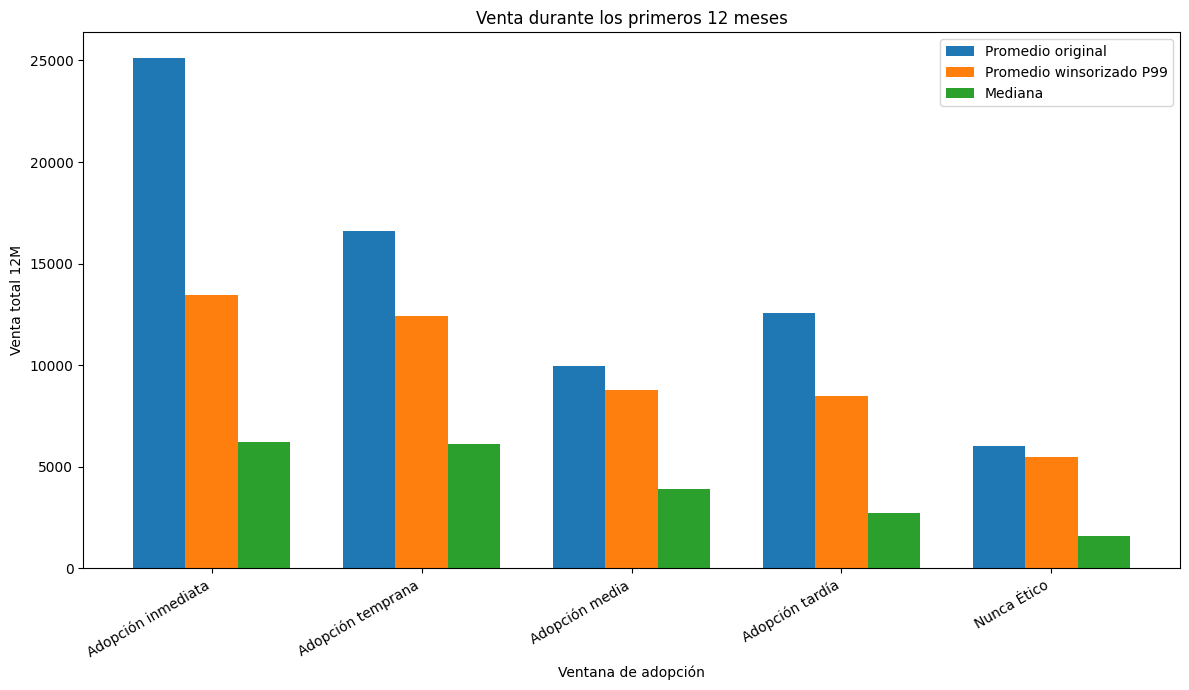

In [112]:
x = np.arange(len(resumen_ventanas))
ancho = 0.25

plt.figure(figsize=(12, 7))

plt.bar(
    x - ancho,
    resumen_ventanas["venta_promedio"],
    width=ancho,
    label="Promedio original"
)

plt.bar(
    x,
    resumen_ventanas["promedio_winsorizado"],
    width=ancho,
    label="Promedio winsorizado P99"
)

plt.bar(
    x + ancho,
    resumen_ventanas["mediana_venta"],
    width=ancho,
    label="Mediana"
)

plt.title("Venta durante los primeros 12 meses")
plt.xlabel("Ventana de adopción")
plt.ylabel("Venta total 12M")

plt.xticks(
    x,
    resumen_ventanas["ventana_adopcion"],
    rotation=30,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

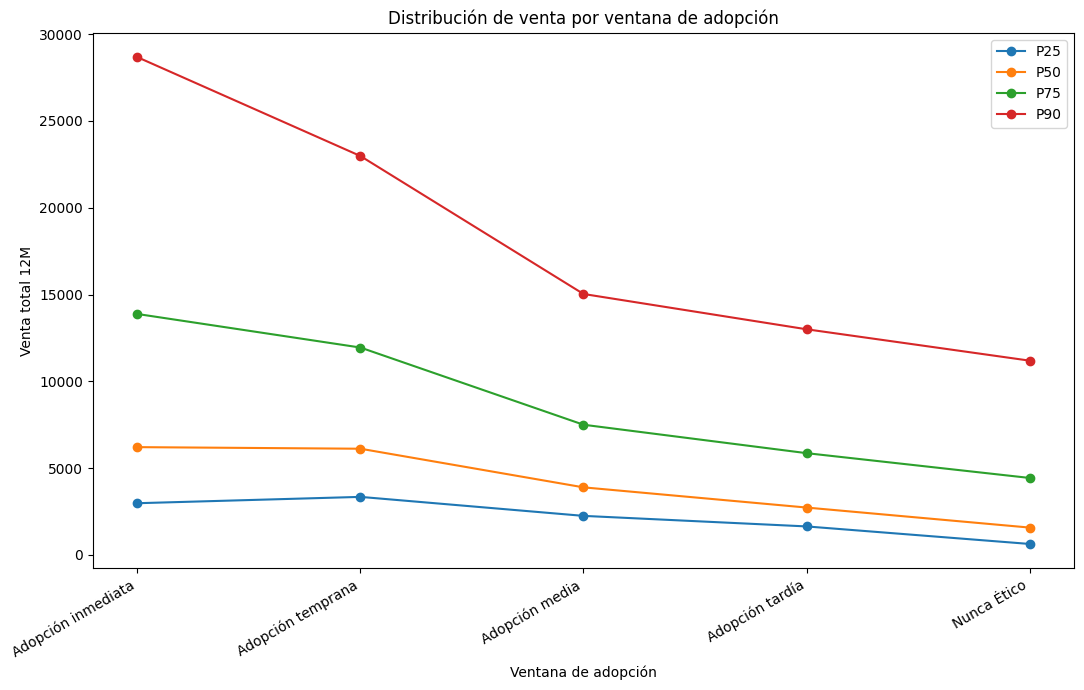

In [113]:
plt.figure(figsize=(11, 7))

for columna in [
    "p25",
    "p50",
    "p75",
    "p90"
]:
    plt.plot(
        resumen_ventanas["ventana_adopcion"],
        resumen_ventanas[columna],
        marker="o",
        label=columna.upper()
    )

plt.title("Distribución de venta por ventana de adopción")
plt.xlabel("Ventana de adopción")
plt.ylabel("Venta total 12M")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

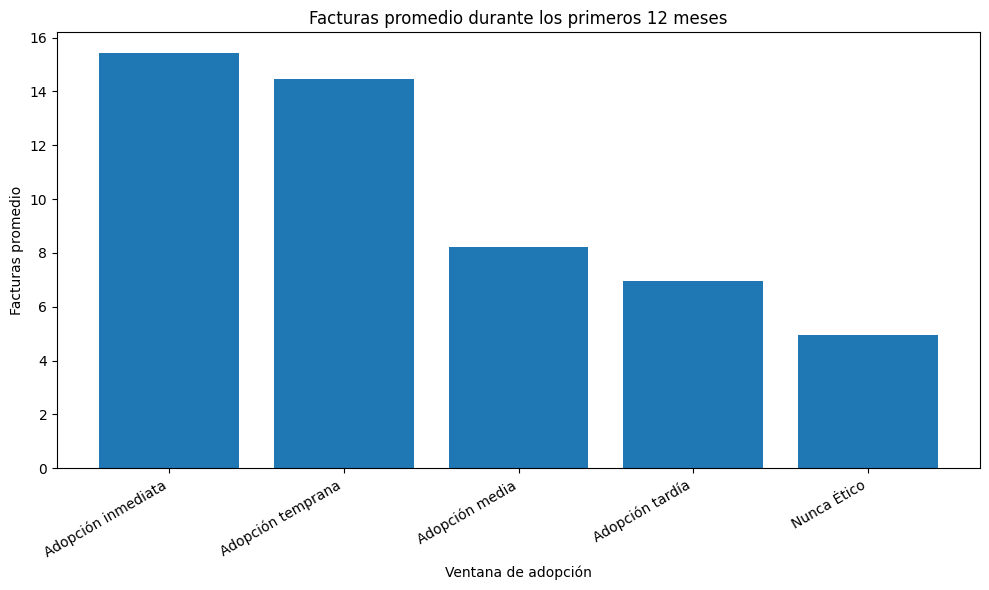

In [114]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumen_ventanas["ventana_adopcion"],
    resumen_ventanas["facturas_promedio"]
)

plt.title("Facturas promedio durante los primeros 12 meses")
plt.xlabel("Ventana de adopción")
plt.ylabel("Facturas promedio")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

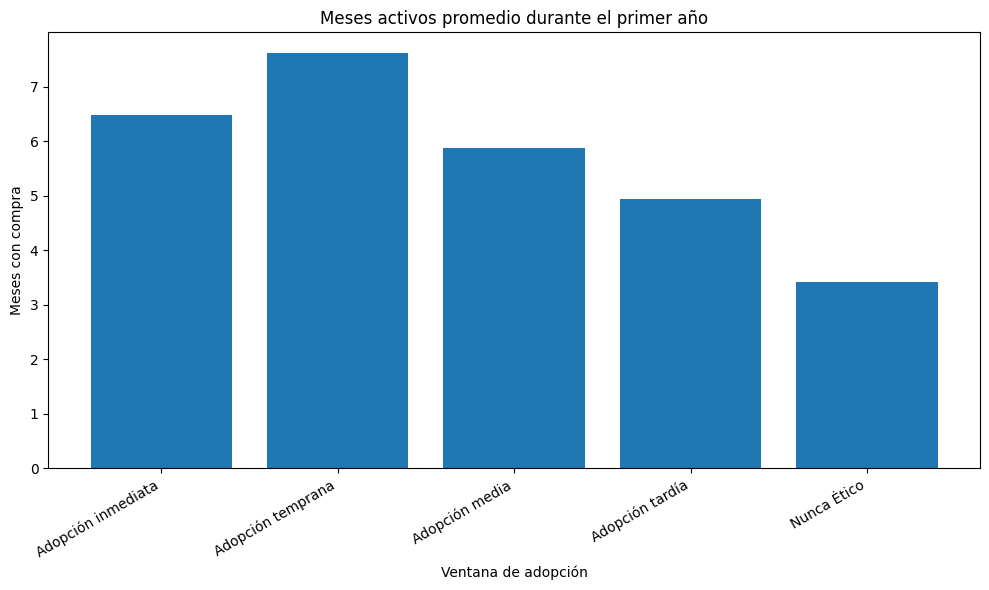

In [115]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumen_ventanas["ventana_adopcion"],
    resumen_ventanas["meses_activos_promedio"]
)

plt.title("Meses activos promedio durante el primer año")
plt.xlabel("Ventana de adopción")
plt.ylabel("Meses con compra")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

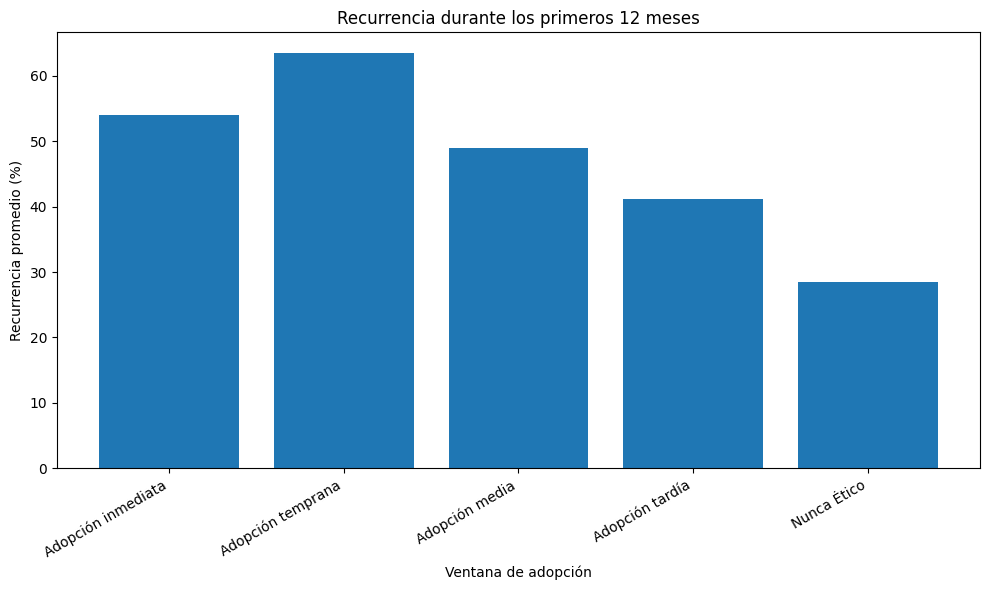

In [116]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumen_ventanas["ventana_adopcion"],
    resumen_ventanas["recurrencia_pct"]
)

plt.title("Recurrencia durante los primeros 12 meses")
plt.xlabel("Ventana de adopción")
plt.ylabel("Recurrencia promedio (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [117]:
referencia = resumen_ventanas.loc[
    resumen_ventanas["ventana_adopcion"] == "Nunca Ético"
].iloc[0]

In [118]:
comparacion_nunca = resumen_ventanas.copy()

In [119]:
comparacion_nunca["ratio_mediana_vs_nunca"] = (
    comparacion_nunca["mediana_venta"]
    / referencia["mediana_venta"]
)

In [120]:
comparacion_nunca["uplift_mediana_vs_nunca_pct"] = (
    (
        comparacion_nunca["mediana_venta"]
        / referencia["mediana_venta"]
    ) - 1
) * 100

In [121]:
comparacion_nunca["uplift_winsor_vs_nunca_pct"] = (
    (
        comparacion_nunca["promedio_winsorizado"]
        / referencia["promedio_winsorizado"]
    ) - 1
) * 100

In [122]:
comparacion_nunca["diferencia_meses_activos"] = (
    comparacion_nunca["meses_activos_promedio"]
    - referencia["meses_activos_promedio"]
)

In [123]:
comparacion_nunca["diferencia_recurrencia_pp"] = (
    comparacion_nunca["recurrencia_pct"]
    - referencia["recurrencia_pct"]
)

In [124]:
display(
    comparacion_nunca[
        [
            "ventana_adopcion",
            "mediana_venta",
            "ratio_mediana_vs_nunca",
            "uplift_mediana_vs_nunca_pct",
            "promedio_winsorizado",
            "uplift_winsor_vs_nunca_pct",
            "diferencia_meses_activos",
            "diferencia_recurrencia_pp"
        ]
    ]
)

,ventana_adopcion,mediana_venta,ratio_mediana_vs_nunca,uplift_mediana_vs_nunca_pct,promedio_winsorizado,uplift_winsor_vs_nunca_pct,diferencia_meses_activos,diferencia_recurrencia_pp
0,Adopción inmediata,"6,206.68",3.95,294.65,"13,437.04",144.54,3.07,25.58
1,Adopción temprana,"6,115.24",3.89,288.84,"12,420.33",126.04,4.20,35.01
2,Adopción media,"3,890.24",2.47,147.36,"8,791.70",60.00,2.46,20.49
3,Adopción tardía,"2,726.48",1.73,73.36,"8,486.51",54.44,1.52,12.71
4,Nunca Ético,"1,572.70",1.00,0.00,"5,494.84",0.00,0.00,0.00


In [125]:
comparacion_nunca["indice_valor_mediano"] = (
    comparacion_nunca["mediana_venta"]
    / referencia["mediana_venta"]
    * 100
)

In [126]:
display(
    comparacion_nunca[
        [
            "ventana_adopcion",
            "mediana_venta",
            "indice_valor_mediano"
        ]
    ]
)

,ventana_adopcion,mediana_venta,indice_valor_mediano
0,Adopción inmediata,"6,206.68",394.65
1,Adopción temprana,"6,115.24",388.84
2,Adopción media,"3,890.24",247.36
3,Adopción tardía,"2,726.48",173.36
4,Nunca Ético,"1,572.70",100.00


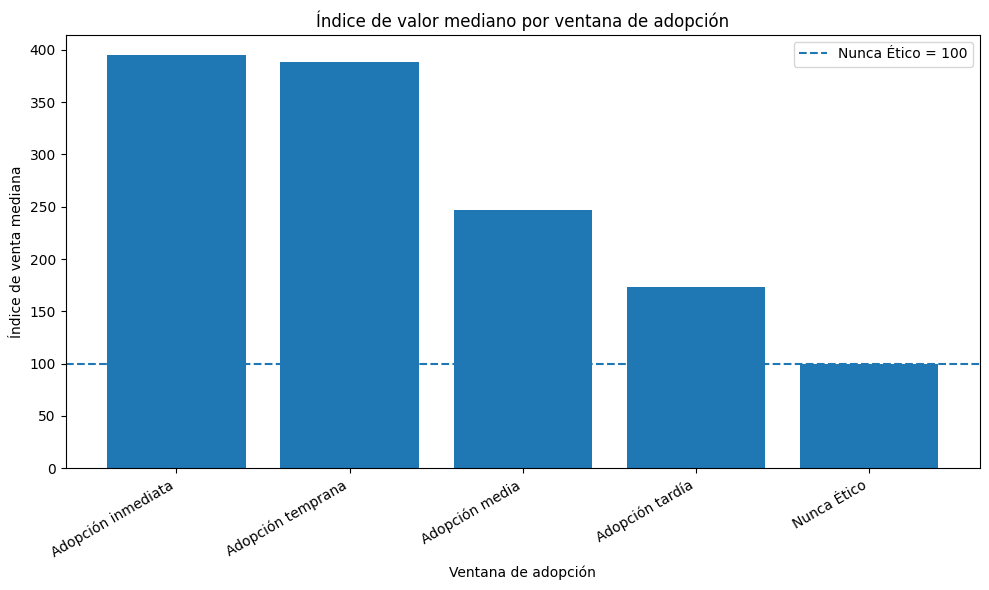

In [127]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparacion_nunca["ventana_adopcion"],
    comparacion_nunca["indice_valor_mediano"]
)

plt.axhline(
    100,
    linestyle="--",
    label="Nunca Ético = 100"
)

plt.title("Índice de valor mediano por ventana de adopción")
plt.xlabel("Ventana de adopción")
plt.ylabel("Índice de venta mediana")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [128]:
corte_top_25 = df["venta_total_12m"].quantile(0.75)

In [129]:
df["es_top_25"] = (
    df["venta_total_12m"]
    >= corte_top_25
).astype(int)

In [130]:
corte_top_10 = df["venta_total_12m"].quantile(0.90)

df["es_top_10"] = (
    df["venta_total_12m"]
    >= corte_top_10
).astype(int)

In [131]:
probabilidad_alto_valor = (
    df
    .groupby(
        "ventana_adopcion",
        observed=True
    )
    .agg(
        clientes=(
            "codigo_cliente",
            "nunique"
        ),

        clientes_top_25=(
            "es_top_25",
            "sum"
        ),

        clientes_top_10=(
            "es_top_10",
            "sum"
        )
    )
    .reset_index()
)

In [132]:
probabilidad_alto_valor["probabilidad_top_25_pct"] = (
    probabilidad_alto_valor["clientes_top_25"]
    / probabilidad_alto_valor["clientes"]
    * 100
)

In [134]:
probabilidad_alto_valor["probabilidad_top_10_pct"] = (
    probabilidad_alto_valor["clientes_top_10"]
    / probabilidad_alto_valor["clientes"]
    * 100
)

In [135]:
display(probabilidad_alto_valor)

,ventana_adopcion,clientes,clientes_top_25,clientes_top_10,probabilidad_top_25_pct,probabilidad_top_10_pct
0,Adopción inmediata,3893,1258,519,32.31,13.33
1,Adopción temprana,684,190,67,27.78,9.80
2,Adopción media,413,65,25,15.74,6.05
3,Adopción tardía,276,32,16,11.59,5.80
4,Nunca Ético,1615,176,62,10.90,3.84


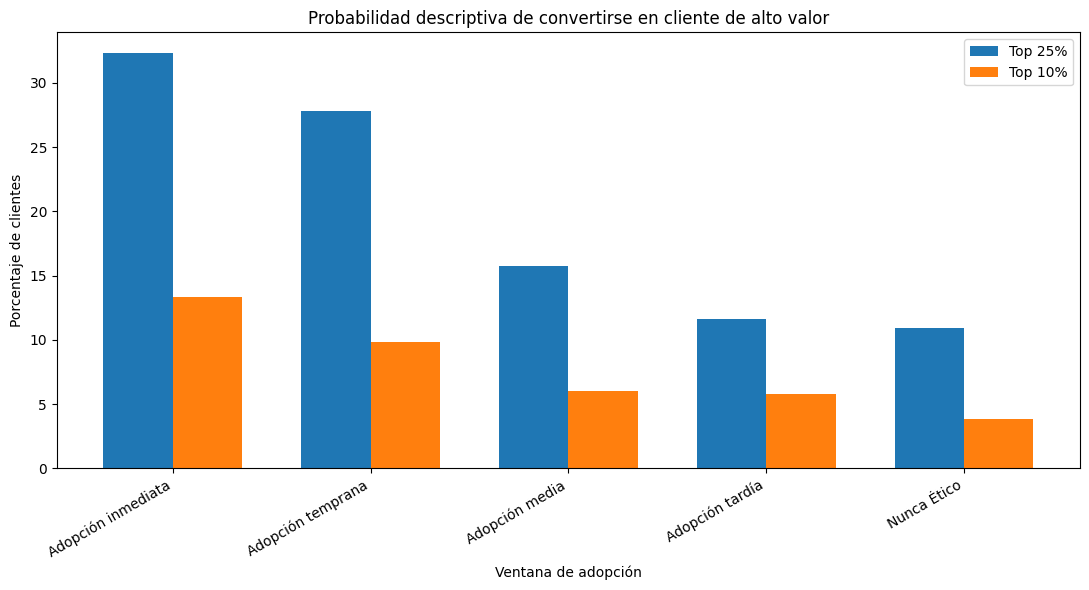

In [136]:
x = np.arange(len(probabilidad_alto_valor))
ancho = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - ancho / 2,
    probabilidad_alto_valor["probabilidad_top_25_pct"],
    width=ancho,
    label="Top 25%"
)

plt.bar(
    x + ancho / 2,
    probabilidad_alto_valor["probabilidad_top_10_pct"],
    width=ancho,
    label="Top 10%"
)

plt.title("Probabilidad descriptiva de convertirse en cliente de alto valor")
plt.xlabel("Ventana de adopción")
plt.ylabel("Porcentaje de clientes")

plt.xticks(
    x,
    probabilidad_alto_valor["ventana_adopcion"],
    rotation=30,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

In [137]:
prob_nunca_top_25 = (
    probabilidad_alto_valor.loc[
        probabilidad_alto_valor["ventana_adopcion"]
        == "Nunca Ético",
        "probabilidad_top_25_pct"
    ]
    .iloc[0]
)

In [138]:
probabilidad_alto_valor["ratio_top_25_vs_nunca"] = (
    probabilidad_alto_valor["probabilidad_top_25_pct"]
    / prob_nunca_top_25
)

In [139]:
display(
    probabilidad_alto_valor[
        [
            "ventana_adopcion",
            "probabilidad_top_25_pct",
            "ratio_top_25_vs_nunca"
        ]
    ]
)

,ventana_adopcion,probabilidad_top_25_pct,ratio_top_25_vs_nunca
0,Adopción inmediata,32.31,2.97
1,Adopción temprana,27.78,2.55
2,Adopción media,15.74,1.44
3,Adopción tardía,11.59,1.06
4,Nunca Ético,10.90,1.00


In [140]:
tabla_ventanas_ejecutiva = (
    resumen_ventanas
    .merge(
        probabilidad_alto_valor[
            [
                "ventana_adopcion",
                "probabilidad_top_25_pct",
                "probabilidad_top_10_pct",
                "ratio_top_25_vs_nunca"
            ]
        ],
        on="ventana_adopcion",
        how="left"
    )
)

In [141]:
tabla_ventanas_ejecutiva = tabla_ventanas_ejecutiva[
    [
        "ventana_adopcion",
        "clientes",
        "participacion_clientes_pct",
        "venta_promedio",
        "promedio_winsorizado",
        "mediana_venta",
        "p25",
        "p75",
        "p90",
        "ticket_promedio",
        "facturas_promedio",
        "meses_activos_promedio",
        "recurrencia_pct",
        "probabilidad_top_25_pct",
        "probabilidad_top_10_pct",
        "ratio_top_25_vs_nunca"
    ]
]

In [ ]:
from pathlib import Path

Path("outputs").mkdir(
    parents=True,
    exist_ok=True
)

In [142]:
resumen_ventanas.to_csv(
    "outputs_resumen_ventanas_adopcion.csv",
    index=False,
    encoding="utf-8-sig"
)

In [143]:
comparacion_nunca.to_csv(
    "outputs_comparacion_ventanas_vs_nunca_etico.csv",
    index=False,
    encoding="utf-8-sig"
)

In [144]:
probabilidad_alto_valor.to_csv(
    "outputs_probabilidad_alto_valor_por_ventana.csv",
    index=False,
    encoding="utf-8-sig"
)

In [145]:
tabla_ventanas_ejecutiva.to_csv(
    "outputs_tabla_ejecutiva_ventanas_adopcion.csv",
    index=False,
    encoding="utf-8-sig"
)